# chip_10a_flux_tlqubits — seven Xmons (two flux-tunable SQUIDs) and eight λ/4 on one feedline (chip_05 revision), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_10a_flux_TLQubits.py` (`create_test_chip()`, writes
`chip_10a_flux_TLQubits_1.0.oas`), Quantcore internal. Spec: `docs/designs/legacy/chip_10a_flux_tlqubits.md` (a
delta on `chip_05_flux_tlqubits.md`); this notebook follows the chip_05 notebook step by step.

A 7.5 × 7.5 mm die with a 5250 µm feedline between two "Connector Pad 2" bond pads; eight Coupled Resonators
alternating below / above it (couplers 300 µm long at 2, 4 or 6 µm ground strips), seven Xmon crosses whose claws
take R1–R7's tails (Q3 / Q5 with thin 20 µm claws, Q6 with the 600 µm cross); trilayer junctions from the
`xjc_junction_TL_mod` / `xjc_squid_TL_mod` scripts (Q4 / Q5 SQUIDs) under 30 × 45 µm junction windows; 4/6 µm flux
lines with a 1 µm tip and a 28 × 5 µm ground slot from two small pads at the top / bottom edges to Q4 / Q5; R8 a
bare resonator with an end cap; eight 8 × 30 arrays of 5 µm flux-trap holes; eight small HSQ junction test pads
(`xtp_testpads_TL_small`, 0.5 and 0.8 µm); labels "500nm", "800nm", "QCG_Nb11_W"; HSQ corner markers.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators, Xmons | the eight `Coupled Resonator`s and seven `Xmon Cross`es (`x_cap_params`) with the legacy parameters, positions and rotations; each tail runs into its claw tail (the source's galvanic join, `W_Qi` wires); R8 with its end cap | — |
| feedline, pads | the "Connector Pad 2" geometry (`BondPad`: 400 × 450 µm pad, 225 µm gap, 450 µm taper), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: at the edge): feedline 5050 µm (legacy 5250) |
| flux lines | 4/6 µm routes from the two small "Connector Pad"s, the legacy x waypoints, a 1 µm tip and the 28 × 5 µm ground slot | the flux pads also 100 µm from the edge; each jog keeps its legacy distance from its pad port (155 / 360 µm), so the corner radii 75 / 100 µm (#11) still fit; the 4 µm straight before the tip is 100 µm shorter |
| junctions | the legacy trilayer cells (`Trilayer Junction`, `Trilayer Squid`) at the legacy fingers (js · 0.1 × 0.6 µm, #1; indexing fixed, #11) under the 30 × 45 µm CLEARER windows | valued on the PDK process: Q1–Q3 45 kΩ; Q6 (js 8) 28.1 kΩ and the SQUIDs Q4 / Q5 22.5 kΩ (parallel) are outside 40–50 kΩ → **flagged** (`pdk_rn`), not retuned |
| cheese | the source's own eight 8 × 30 arrays of 5 µm holes (`FluxHoleArray`) | none added: **the original's cheese wins** (`cheese: "original"`) |
| placement | everything relative to the feedline; the labels where the source puts them | the circuit **centred in the die** where it is more than 50 µm off (step 7; labels left out of the measure) |
| frame | the HSQ corner markers (`CornerMarker`, `hsq=True`) | the PDK die frame and device ID `CHIP10A` instead of the legacy base-metal `Marker` corners and the 10/0 outline |

**Approximations** : the flux lines are Designer routes into the Xmon's
flux port (default flux tip: 10.5 µm off the axis, 0.5 µm into the ground, the 28 × 5 µm slot = the legacy box);
the route runs at x = −267.5 / 271.5 (the tip's x) where the legacy path runs at −267 / 271 (0.5 µm off its own
tip), and the step to the 1 µm tip is a 1 µm KQC taper (legacy: abrupt). The junction windows (legacy CLEARER, 30 ×
45 µm) are `Xmon.junction_window`: `[30, 45, 12.5]` for the junctions (from the cross end 25 µm into the ground),
`[30, 45, −12.5]` for the SQUIDs (shifted 25 µm into the cross); metal on `base_metal_addition`, removed from the
1/0 etch at export (the FEM export drops the window). The legacy inserts each junction cell unrotated, mirrored by a
toggling flag (Q2, Q6); here the junction rotates with its Xmon and `mirror_squid` on Q2 / Q6 gives the same mirror.
Q4 cannot match: the flag toggles twice for a SQUID, so the legacy Q4 SQUID sits upside down relative to its island
and ground; the rebuild keeps it oriented like Q5 (kept).

**Reproduced exactly** (XOR against the author's legacy PCells and scripts, read-only through `tests/legacy_ref`, step
15): the resonators, crosses and claws with their junction windows, the holes, the test pads, the labels and the
pads + feedline at their PDK position; the junction cells on the junction layers (2/0, 4/0, HSQ) except Q4's
orientation.

### Changes after design review (2026-11-03)

- **Junction indexing — fixed** (on chip_05; this chip is its later version with the same `bot[i-1]` loop):
  Q1–Q5 now js 5 (0.5 µm), Q6 (600 µm cross) js 8 (0.8 µm); the junction-layer reference in step 15 calls the
  legacy scripts with the same fixed sizes.
- **Flux-line corners** (no break / overlap): each line takes the largest radius the router fits —
  FLUX5 the legacy 100 µm (360 µm pad lead, 271.5 µm jog), FLUX4 75 µm (its 155 µm pad lead cannot hold a 100 µm
  bend: "straight segment cannot fit"); was r = 50 on both. Same waypoints, 4/6 µm CPW and 1 µm tip.
- **#25 Q4 SQUID orientation:** kept as rebuilt (oriented like Q5); confirmed.
- **#1 / PDK rebuild — junctions.** The legacy trilayer cells (`Trilayer Junction` / `Trilayer Squid`, the xjc TL
  scripts: fingers on 2/0 + 4/0 with the spacer) stay at the legacy fingers, valued on the **PDK junction rule**
  (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV; PDK process R_n·A 13.5 kΩ·µm², assumed by the PDK, = 45 kΩ at
  0.5 × 0.6 µm): Q1–Q3 45 kΩ (L_J 6.73 nH), Q6 28 kΩ, SQUIDs Q4/Q5 22.5 kΩ in parallel at zero flux. The earlier
  assumed J_c = 1 µA/µm² is gone. Values in step 10.
- **Claw-tail gap (#22):** the Xmon's claw tail is cleared by its own `claw_tail_gap` (default: the
  chip CPW gap, 6 µm); `L.xmon` sets it to the legacy `cap_spacing` = 6 µm, as the legacy `Xmon Cross` draws it,
  matching the 10/6 µm resonators.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** the left bond pad is placed with `edge="auto"` (outer etch `get_pdk().frame.pad_edge` = 100 µm from
  the die edge), the feedline snaps onto its port with the length the rule leaves on this symmetric chip, and the
  right pad snaps onto the far end (before: the feedline at (0, 0) with both pads snapped to it). The flux pads
  `PFT` / `PFB` get `edge="auto"` too. DRC `pad_edge` warnings: 4 → 0.
- **Flux lines:** each route follows its moved pad: the jog keeps its legacy distance from the pad port (FLUX4 155
  µm, FLUX5 360 µm), so the legacy corner radii (75 / 100 µm) still fit; the 1 µm tip and the slot are unchanged.
- **Centring:** `L.center_circuit` (labels left out of the measure, moved with everything; each axis only if > 50
  µm off).
- **Cheese:** the source etches its own flux holes, so the original wins: `cheese: "original"` (before this pass
  the chip was `"auto"` and the build added the PDK band on top of the holes).
- **Junctions:** the legacy trilayer cells at the legacy fingers (decision #1); `pdk_rn` flags them where they
  leave 40–50 kΩ, never retuned.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks (`_legacy_b`, `LB`, adds the legacy cells of the later chips). `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # Connector Pad 2, holes, labels, xjc scripts, junction XOR
from quantcore_circuits.assembly.drc import device_id_block
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_10a_flux_tlqubits", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'original — the source etches eight 8 × 30 arrays of 5 µm flux holes (FluxHoleArray); no PDK band'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches eight 8 × 30 arrays of 5 µm flux holes (FluxHoleArray); no PDK band |

### The source's numbers

`chip_10a_flux_TLQubits.py`'s numbers in its own (0, 0)-centred frame (µm); `L.place` shifts them by (+3750, +3750)
into the Designer frame; `L.xmon`, `L.coupled_resonator`, `L.connector_pad`, `L.cpw_segment` map the legacy PCell
parameters, and `BOND` is "Connector Pad 2" as a `BondPad`. Rows: each resonator (coupler x, ground strip, above /
below, overrides, target), each Xmon (legacy centre, cross, js), the flux lines (pad, the legacy jog distance from
the pad port, jog x, the 1 µm tip's start, corner radius), holes, test pads and labels.

In [4]:
# chip_10a_flux_TLQubits.py, legacy frame (µm)
FEED = dict(length=7500 - 2000 - 40 - 210, gap=6, lc_thickness=2, rc_thickness=2)    # "Coplanar Waveguide", 5250 µm
PAD2 = dict(trace_width=10, pad_gap=225, pad_height=450, pad_width=400, conn_height=450, round=False, sim=False)
BOND = dict(pad_width=400, pad_gap=225, pad_height=450, taper_length=450, a=10, b=6, rounded=False)  # PAD2 → BondPad
TINY = dict(trace_width=4, pad_height=150, pad_width=400, conn_height=100, round=True, sim=False)    # flux pads
X_PAD, Y_TINY = 3750 - 1000 - 125, 3750 - 500 - 70 - 25                                            # 2625, 3155
RES = dict(cpw_len=4660, gap=6, clength=300, cgap=4, width=304, flip=False, neck_length=400, ground=False)
#         n  x_res strip above  overrides                                  f (GHz)   strip = cgap[k]: y = ±(22 + strip)
RROWS = [(1, -2000, 2, False, dict(cpw_len=4740),                          6.5),
         (2, -1430, 4, True,  dict(cpw_len=4920, flip=True),               6.25),
         (3,  -850, 4, False, dict(cpw_len=5590, flip=True),               5.5),
         (4,  -280, 2, True,  dict(cpw_len=6000),                          5.0),
         (5,   280, 4, False, dict(cpw_len=5200),                          6.0),
         (6,   850, 4, True,  dict(cpw_len=4250),                          7.2),
         (7,  1430, 6, False, dict(cpw_len=5840, flip=True),               5.25),
         (8,  2000, 6, True,  dict(cpw_len=4500, flip=True, ground=True),  7.0)]    # R8: no qubit, end cap
XCAP = dict(width=400, handle=1, cap_spacing=6, da=1, thickness=50, pthickness=35, fwidth=35, spacing=20, ggap=6,
            hlength=130)                                                            # x_cap_params
XBIG, GX = XCAP | dict(width=600, hlength=150), XCAP | dict(pthickness=20, fwidth=50, hlength=150)
#          x      y    cross  junction (js · 0.1 µm: bot[i]; the legacy bot[i-1] bug fixed as on chip_05, #11)
QUBITS = [(-1998, -2077, XCAP, 5), (-1432, 2259, XCAP, 5), (-852, -2500, GX, 5), (-278, 2492, XCAP, 5),
          (282, -2110, GX, 5), (852, 2098, XBIG, 8), (1428, -2345, XCAP, None)]       # Q7: no junction
SQUIDS, SECOND_FINGER = (4, 5), 0.6                                                 # xjc_squid_TL_mod for Q4, Q5
MIRROR = (2, 6)         # the source's toggling Trans(0, flag) junction mirror: on a 180° Xmon = mirror_squid
WINDOW = {"jj": [30, 45, 12.5], "squid": [30, 45, -12.5]}   # legacy CLEARER: from the cross end / 25 µm inside it
USE_WINDOWS = True      # the FEM export drops the windows (the simulated junction is the lumped port)
#        flux pad, jog distance from its port (legacy), jog x, start of the 1 µm tip (legacy y), corner radius (#11)
FLUX = {4: ("PFT", 155, -267.5, 2770, 75),     # legacy: port y 3155, jog y 3000; its 155 µm lead holds r ≤ 75
        5: ("PFB", 360, 271.5, -2490, 100)}    # legacy: port y −3155, jog y −2795; the legacy r 100
HOLES = list(zip([-2090, -1520, -920, -340, 180, 770, 1350, 2000], [65, -1500] * 4))   # first hole at (x - 50, y)
TESTPADS = [(-3000 + 200 * k, 2000, 0.5) for k in range(4)] + [(3000 - 200 * k, -2000, 0.8) for k in range(4)]
LABELS = [("LBL_500", "500nm", -3050, 1580), ("LBL_800", "800nm", 2350, -2400), ("LBL_SIGN", "QCG_Nb11_W", 1275, -3100)]

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die. The PDK frame is drawn on every build: four L-shaped
dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID `CHIP10A`
(`name_chip`). `cheese="original"`: this design brings its own cheese (the flux holes, step 7), so the build adds no
PDK band.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


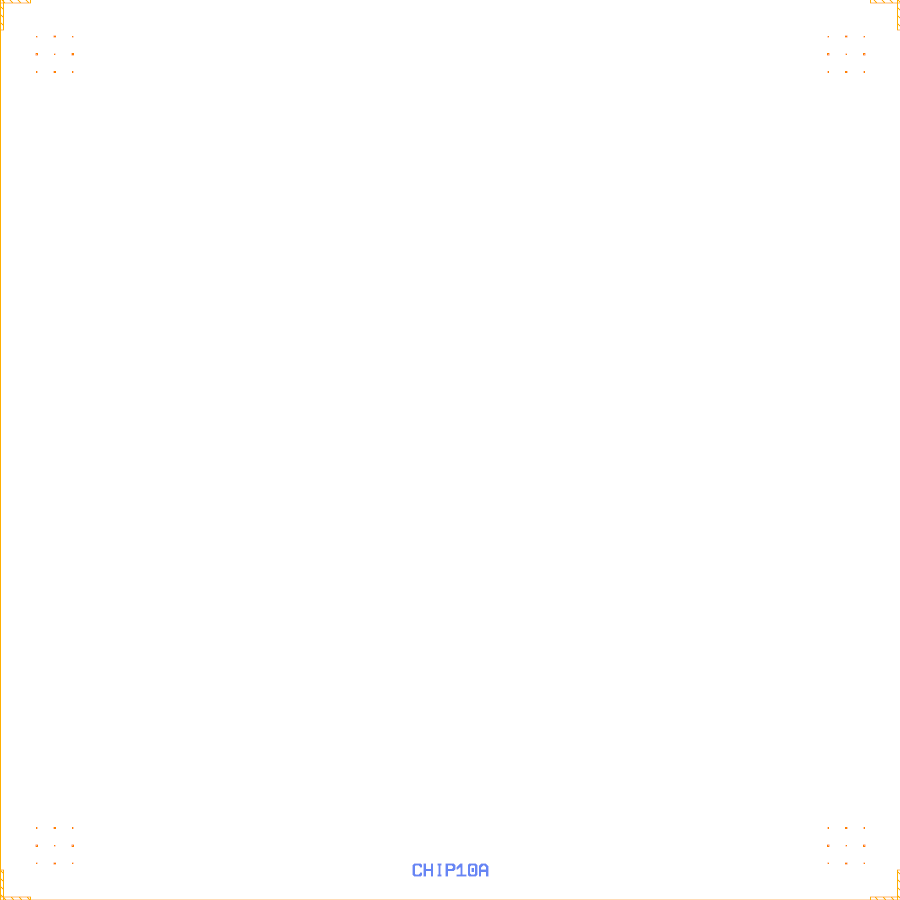

WindowsPath('build/legacy_steps/chip_10a_flux_tlqubits_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP10A", "cheese": "original"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The legacy "Connector Pad 2" (`BondPad`: 400 × 450 µm pad in a 225 µm gap, 450 µm taper, square) goes at the left
end of the feedline with the legacy rotation (rot 3); `edge="auto"` slides it perpendicular to its nearest die edge
until the outer edge of its etch is **`pad_edge` = 100 µm** from the die edge (`get_pdk().frame.pad_edge`, the
design-area margin): the PDK pad rule wins over the original (whose pads reached the die edge).

The feedline (`CpwSegment`, 10/6 µm) snaps onto the left pad's port with the length the rule leaves on this
symmetric chip, and the right pad snaps onto its far end: pad, feedline and pad are one conductor. The two small
flux pads (`ConnectorPad`, 400 × 150 µm, 4 µm trace) keep their legacy x and get `edge="auto"` as well, so their
ports move 100 µm towards the centre. `L.edge_gaps` measures the four pads from the built etch; `device_id_block`
says where the frame put the device ID.

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0, 'PFT': 100.0, 'PFB': 100.0} | rule: 100.0
feedline 5050 µm (legacy 5250 µm) | flux-pad ports, legacy frame y: [3055.0, -3055.0] (legacy ±3155)


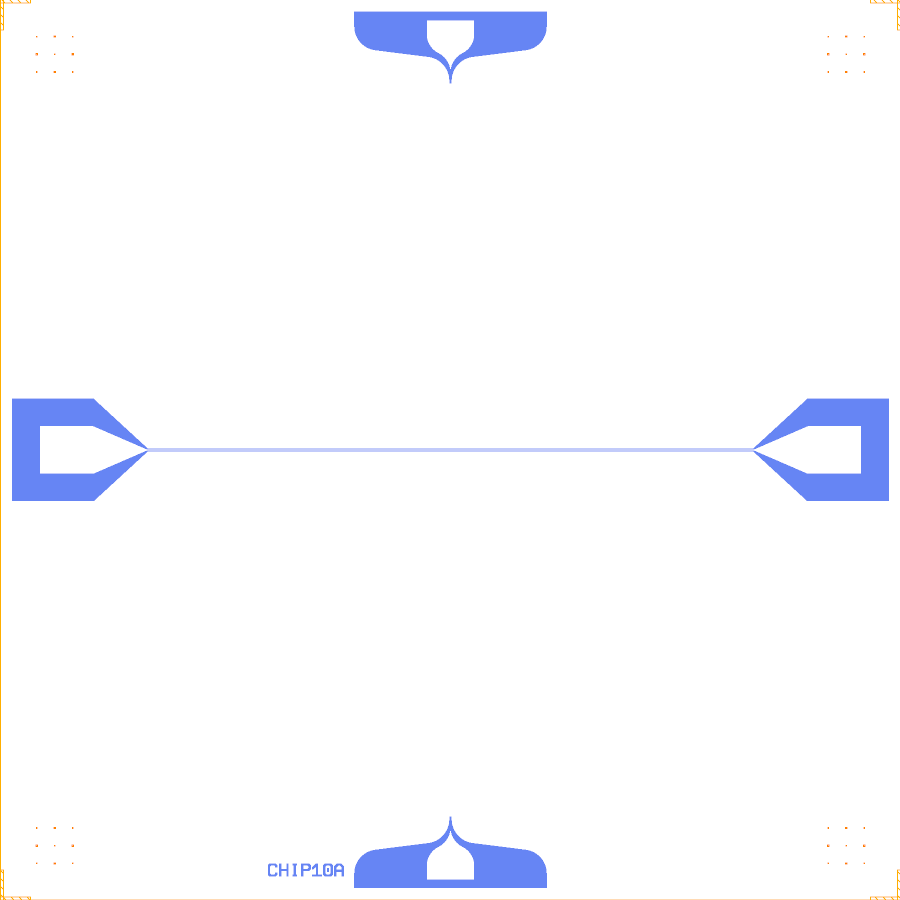

device ID block (µm): (2195,100;2895,400)


In [6]:
d.add("PL", "BondPad", **L.place(-2400, 0, 3), edge="auto", **BOND)               # legacy port (−2625, 0), rot 3
x_pad = L.W / 2 - C.port_xy(d, "PL.a")[0]          # feedline half-length the rule leaves (legacy frame)
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED | {"length": round(2 * x_pad, 3)}))
    d.add("PR", "BondPad", snap="a", to="FL.b", **BOND)                              # legacy (+2625, 0), rot 1
    d.add("PFT", "ConnectorPad", **L.place(0, Y_TINY, 2, False), edge="auto", **L.connector_pad(**TINY))  # "cpadB"
    d.add("PFB", "ConnectorPad", **L.place(0, -Y_TINY, 2, True), edge="auto", **L.connector_pad(**TINY))  # "cpadT"
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
print(f"feedline {2 * x_pad:.0f} µm (legacy {FEED['length']} µm) | flux-pad ports, legacy frame y:",
      [round(C.port_xy(d, p)[1] - L.H / 2, 1) for p in ("PFT.a", "PFB.a")], f"(legacy ±{Y_TINY})")
L.step_snapshot(d, "2_pads")
print("device ID block (µm):", device_id_block(d.result))

## 5 · Components: resonators, Xmons and their junctions

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell: a meandered 10/6 µm λ/4 (`cpw_len`), shorted at
the end of its 300 µm coupler beside the feedline behind a 2, 4 or 6 µm ground strip (the coupler's y follows the
strip: ±(22 + strip)). R1–R7 end uncapped (`ground=False`) and their tail runs into the Xmon's claw tail as the
source places them; `d.couple("W_Qi", "Qi.claw_n", "Ri.end", wire=True)` declares that galvanic join. R8 (no qubit)
has its end cap (`ground=True`). `d.couple("K_Ri", "Ri", "FL")` declares the hanger coupling; `d.targets` stores
the source's frequencies. Q4 / Q5 get a flux port (the default flux tip and its 28 × 5 µm slot).

**Junctions.** The xjc trilayer cells (`Trilayer Junction`, Q4 / Q5 `Trilayer Squid`: fingers on 2/0 + 4/0 with the
spacer) at the **legacy fingers**, js · 0.1 µm × 0.6 µm (`junction_params`), under the legacy windows.
`L.jj` values them on the PDK process: js 5 → 45 kΩ (the PDK nominal); Q6's js 8 → 28.1 kΩ and the SQUIDs 22.5 kΩ
(parallel) are outside 40–50 kΩ, so DRC flags them (`pdk_rn`, step 8) — never retuned. Q7 has no junction.

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).


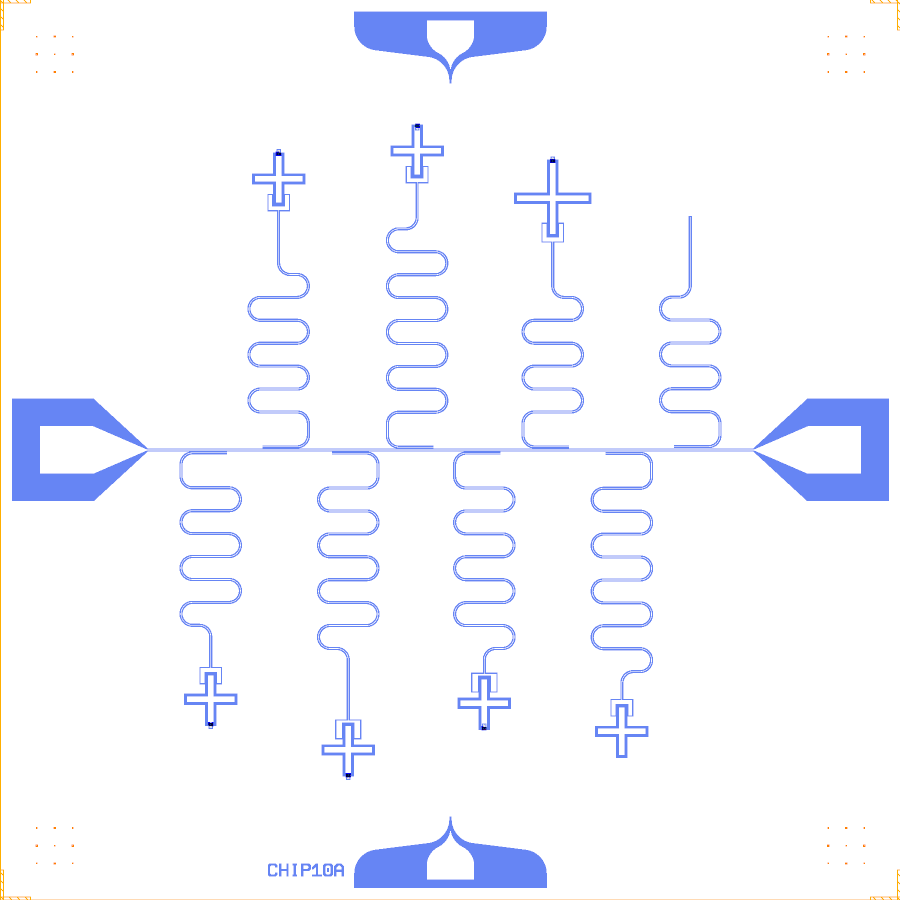

WindowsPath('build/legacy_steps/chip_10a_flux_tlqubits_3_components.png')

In [7]:
with d.batch():
    for n, x, strip, above, over, f in RROWS:
        d.add(f"R{n}", "CoupledResonator", **L.place(x, (22 + strip) * (1 if above else -1), 0, above),
              **L.coupled_resonator(**RES | over))
        d.couple(f"K_R{n}", f"R{n}", "FL", note=f"coupler parallel to the feedline, {strip} µm ground strip")
        d.targets(**{f"R{n}": {"f_GHz": f}})
    for i, (x, y, cross, js) in enumerate(QUBITS, 1):
        squid = i in SQUIDS
        jj = dict(junction_type="Trilayer Squid" if squid else "Trilayer Junction",
                  junction_params={"finger_width": 0.1 * js, "second_finger_width": SECOND_FINGER},
                  junction=L.jj(0.1 * js, SECOND_FINGER, n=2 if squid else 1),
                  junction_window=WINDOW["squid" if squid else "jj"] if USE_WINDOWS else [],
                  mirror_squid=i in MIRROR) if js else dict(junction_type="No Squid")
        d.add(f"Q{i}", "Xmon", **L.place(x, y, 0 if i % 2 else 2), **L.xmon(**cross), flux_port=squid, **jj)
        d.couple(f"W_Q{i}", f"Q{i}.claw_n", f"R{i}.end", wire=True, note="tail without end cap inside the claw tail")
        if js:
            d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}"])
print(L.rule_md())
L.step_snapshot(d, "3_components")

## 6 · Routes: the flux lines

The two flux lines are Designer routes (`d.route`, 4/6 µm CPW) from the flux pads' ports into the Xmon flux ports:
straight down (up) from the pad to a jog, across to the qubit's x, then a 1 µm KQC taper to the 1 µm tip
(`d.waypoint(..., a=1, b=7.5, taper_length=1)` at the legacy tip start) that runs into the SQUID's flux port. The
pads moved 100 µm in (step 4), so each jog is placed at its **legacy distance from the moved pad port** (FLUX4 155
µm, FLUX5 360 µm), computed from the placed pad: the corner radii of the design decision (FLUX4 75 µm, FLUX5 the
legacy 100 µm) still fit, and the 4 µm straight before the tip is 100 µm shorter. In the netlist each flux line is
a control line of its qubit (no circuit element).

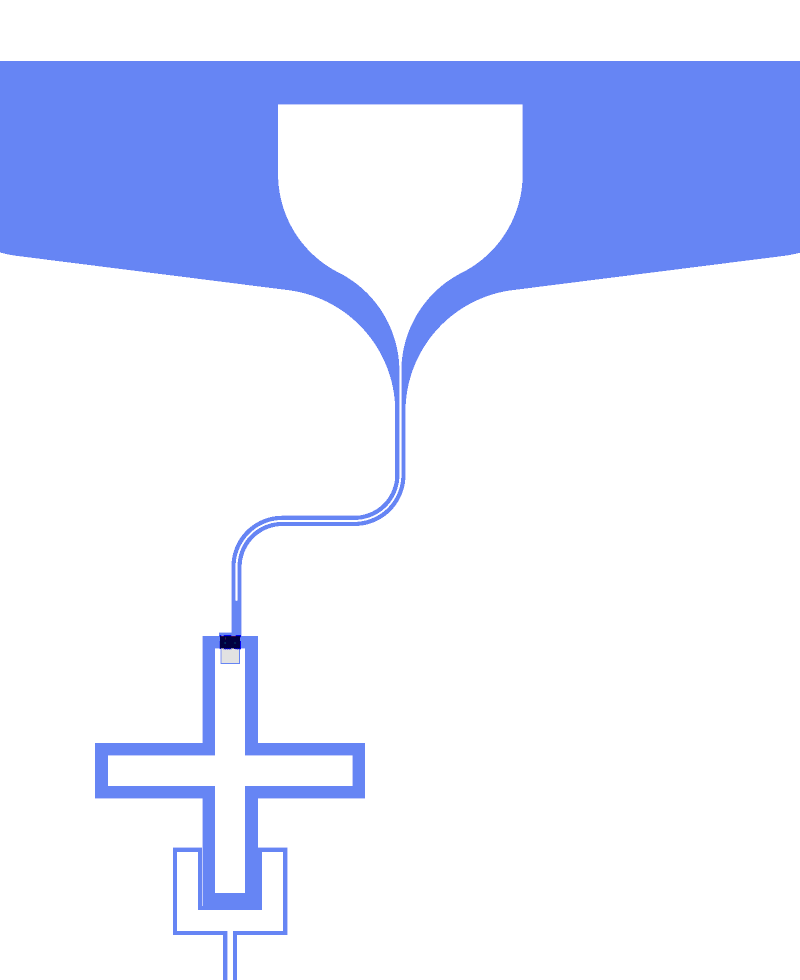

FLUX4: jog y +2900.0 (legacy 3000), 155 µm from PFT.a, r = 75 µm, 4 µm straight after the corner 55.0 µm, length 545.6 µm
FLUX5: jog y -2695.0 (legacy −2795), 360 µm from PFB.a, r = 100 µm, 4 µm straight after the corner 105.0 µm, length 910.2 µm


In [8]:
JOG = {}
for q, (pad, lead, x_jog, y_thin, r) in FLUX.items():
    x0, y0 = C.port_xy(d, f"{pad}.a")
    JOG[q] = y0 - lead if y0 > L.H / 2 else y0 + lead          # the jog keeps its legacy distance from the moved pad
with d.batch():
    for q, (pad, lead, x_jog, y_thin, r) in FLUX.items():
        d.route(f"FLUX{q}", f"{pad}.a", f"Q{q}.flux", a=4, b=6, r=r,
                nodes=[L.at(0, JOG[q] - L.H / 2), L.at(x_jog, JOG[q] - L.H / 2),
                       d.waypoint(L.at(x_jog, y_thin), a=1, b=7.5, taper_length=1)])   # legacy: abrupt 4 → 1 µm
L.step_snapshot(d, "4_flux", box=(3100, 5900, 4400, 7500), size=(800, 980), width=400)
for q, (pad, lead, x_jog, y_thin, r) in FLUX.items():
    print(f"FLUX{q}: jog y {JOG[q] - L.H / 2:+.1f} (legacy {'3000' if q == 4 else '−2795'}), {lead} µm from {pad}.a, "
          f"r = {r} µm, 4 µm straight after the corner {abs(JOG[q] - L.at(0, y_thin)[1]) - r:.1f} µm, "
          f"length {d.result.route_lengths()[f'FLUX{q}']:.1f} µm")

## 7 · The source's cheese, test pads, labels and markers, and centring

**Cheese — the original wins.** The source etches its own flux-trapping holes: eight arrays of 8 × 30 squares of
5 µm on a 50 µm pitch beside the resonators (`FluxHoleArray`, drawn on 1/0). The chip keeps `cheese="original"`
(step 3), so the build adds no PDK band. The eight small HSQ junction test pads (`JunctionTestPads`,
`xtp_testpads_TL_small` with the 0.5 and 0.8 µm fingers), the three labels (`TextLabel`) and the four HSQ corner
markers keep their legacy places; none has a port.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes, the free labels
left out) and shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off.
Then the design is saved.

centring shift (µm):

 (0.0, 0.0) | feedline y = 3750.0 | <Designer chip_10a_flux_tlqubits: 43 instances, 2 routes, live=False> → examples\designs\legacy\chip_10a_flux_tlqubits.json


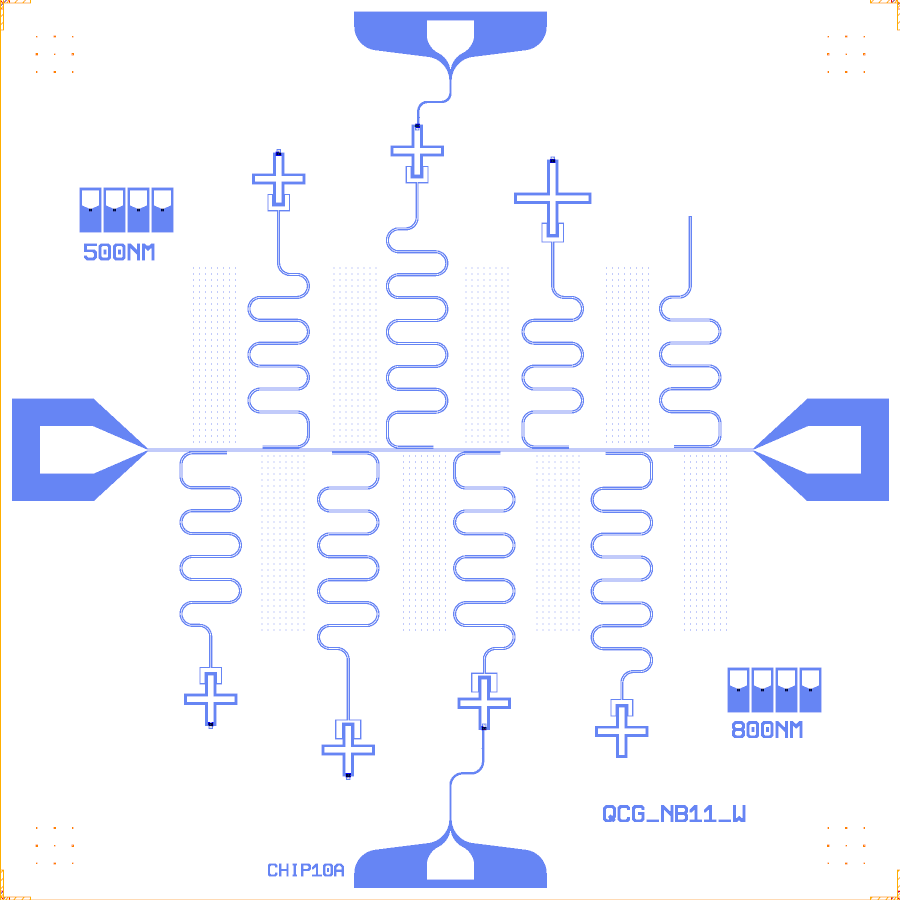

device ID block after the labels and markers (µm): (2195,100;2895,400)


In [9]:
with d.batch():
    for k, (x, y) in enumerate(HOLES):
        d.add(f"H{k}", "FluxHoleArray", **L.place(x - 50, y), hole_size=5, pitch_x=50, pitch_y=50, nx=8, ny=30)
    for k, (x, y, bf) in enumerate(TESTPADS, 1):
        d.add(f"TP{k}", "JunctionTestPads", **L.place(x, y),
              **legacy_test_pad_params("xtp_testpads_TL_small", bf / 0.2, SECOND_FINGER))
    for name, text, x, y in LABELS:
        d.add(name, "TextLabel", **L.place(x, y), text=text, mag=200, inverted=False)
    for k, (x, y, rot) in enumerate([(-3750, -3750, 1), (3750, -3750, 2), (3750, 3750, 3), (-3750, 3750, 0)]):
        d.add(f"HSQ{k}", "CornerMarker", **L.place(x, y, rot), hsq=True, thickness=50, width=150)
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "5_centred")
print("device ID block after the labels and markers (µm):", device_id_block(d.result))

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run), all from legacy choices kept as drawn (as on chip_05): zero errors; `dangling_port` `R8.end`
(R8 is the bare resonator; its end is the open end cap); `frame_margin` / `frame_keepout` HSQ0–HSQ3 (the HSQ
markers at the die corners reach into the dicing margin and the dicing-marker areas: HSQ layer, not the base
metal); `overlap` Qi / Ri, i = 1 … 7 (each claw takes its resonator's tail: the `W_Qi` wires); **3 PDK design
warnings** `pdk_rn`: the SQUIDs Q4 and Q5 (22.5 kΩ in parallel, L_J 3.37 nH) and Q6 (js 8: 28.1 kΩ, L_J 4.21 nH),
outside 40–50 kΩ — flagged, not retuned. No `pad_edge` (all four pads at 100 µm) and no device-ID warning: the four
edge centres hold pads, so the frame put `CHIP10A` beside the bottom flux pad, on its left, (2195, 100)–(2895, 400)
µm. `pdk_report`: cheese "the original design's own", content centre (+0, +0) µm (labels left out), junction types
`Trilayer Junction` × 4, `Trilayer Squid` × 2, `No Squid` × 1.

In [10]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R8.end is not connected (no route or snap)
warning frame_margin  HSQ0 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ0 overlaps the dicing_markers_sw
warning frame_margin  HSQ1 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ1 overlaps the dicing_markers_se
warning frame_margin  HSQ2 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ2 overlaps the dicing_markers_ne
warning frame_margin  HSQ3 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ3 overlaps the dicing_markers_nw
design  pdk_rn        Q4: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH)
design  pdk_rn        Q5: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH)
design  pdk_rn        Q6: junction R_n 28.1 kΩ is outside the PDK window 40–50 kΩ (L_J 4.209 nH)
warning overlap       Q1 and R1 overlap
warning overlap       Q2 and R2 overlap
warning overla

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Trilayer Junction × 4, Trilayer Squid × 2, No Squid × 1 |
| PDK design warnings | 3 (pdk_rn × 3) |
| pdk_rn | Q4: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH) |
| pdk_rn | Q5: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH) |
| pdk_rn | Q6: junction R_n 28.1 kΩ is outside the PDK window 40–50 kΩ (L_J 4.209 nH) |

## 9 · Netlist and LOM

`FL.line` joins both snapped bond pads (50 Ω each). Each `CoupledResonator` → a λ/4 `TLres` (shorted at its
coupler) with a `HANGER` κ to the feedline; R1–R7 end on an Xmon claw node (`W_Qi` merges them); R8 ends at its end
cap. Xmons: island (C, junction / SQUID to ground; Q7 none) + claw node (C_g, C to ground). FLUX4 / FLUX5 are
flux-bias control lines of Q4 / Q5. Holes, labels, markers and test pads have no circuit role.

In [11]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**17 nodes · 45 branches · 2 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R1.res` | `R1.res`, `Q1.claw_n` |
| `R2.res` | `R2.res`, `Q2.claw_n` |
| `R3.res` | `R3.res`, `Q3.claw_n` |
| `R4.res` | `R4.res`, `Q4.claw_n` |
| `R5.res` | `R5.res`, `Q5.claw_n` |
| `R6.res` | `R6.res`, `Q6.claw_n` |
| `R7.res` | `R7.res`, `Q7.claw_n` |
| `R8.res` | `R8.res` |
| `Q1` | `Q1.island` |
| `Q2` | `Q2.island` |
| `Q3` | `Q3.island` |
| `Q4` | `Q4.island` |
| `Q5` | `Q5.island` |
| `Q6` | `Q6.island` |
| `Q7` | `Q7.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 85.4 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `R1.res` | 4.12 fF |
| `Cc_Q1_claw_n` | C | `R1.res` – `gnd` | 94.2 fF |
| `C_Q2` | C | `Q2` – `gnd` | 85.4 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_claw_n` | C | `Q2` – `R2.res` | 4.12 fF |
| `Cc_Q2_claw_n` | C | `R2.res` – `gnd` | 94.2 fF |
| `C_Q3` | C | `Q3` – `gnd` | 85.4 fF |
| `J_Q3` | JJ | `Q3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_claw_n` | C | `Q3` – `R3.res` | 4.75 fF |
| `Cc_Q3_claw_n` | C | `R3.res` – `gnd` | 106 fF |
| `C_Q4` | C | `Q4` – `gnd` | 85.4 fF |
| `J_Q4` | SQUID | `Q4` – `gnd` | Lj 3.37 nH, Cj 30 fF |
| `Cg_Q4_claw_n` | C | `Q4` – `R4.res` | 4.12 fF |
| `Cc_Q4_claw_n` | C | `R4.res` – `gnd` | 94.2 fF |
| `C_Q5` | C | `Q5` – `gnd` | 85.4 fF |
| `J_Q5` | SQUID | `Q5` – `gnd` | Lj 3.37 nH, Cj 30 fF |
| `Cg_Q5_claw_n` | C | `Q5` – `R5.res` | 4.75 fF |
| `Cc_Q5_claw_n` | C | `R5.res` – `gnd` | 106 fF |
| `C_Q6` | C | `Q6` – `gnd` | 128 fF |
| `J_Q6` | JJ | `Q6` – `gnd` | Lj 4.21 nH, Cj 24 fF |
| `Cg_Q6_claw_n` | C | `Q6` – `R6.res` | 4.75 fF |
| `Cc_Q6_claw_n` | C | `R6.res` – `gnd` | 106 fF |
| `C_Q7` | C | `Q7` – `gnd` | 85.4 fF |
| `Cg_Q7_claw_n` | C | `Q7` – `R7.res` | 4.12 fF |
| `Cc_Q7_claw_n` | C | `R7.res` – `gnd` | 94.2 fF |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 4740 µm, 6.647 GHz |
| `K_R1` | HANGER | `R1.res` – `FL.line` | κ 0.273 MHz (L 300 µm) |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 4920 µm, 6.404 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.245 MHz (L 300 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5590 µm, 5.637 GHz |
| `K_R3` | HANGER | `R3.res` – `FL.line` | κ 0.167 MHz (L 300 µm) |
| `R4` | TLres | `R4.res` – `gnd` | lambda/4, 6000 µm, 5.251 GHz |
| `K_R4` | HANGER | `R4.res` – `FL.line` | κ 0.135 MHz (L 300 µm) |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 5200 µm, 6.059 GHz |
| `K_R5` | HANGER | `R5.res` – `FL.line` | κ 0.207 MHz (L 300 µm) |
| `R6` | TLres | `R6.res` – `gnd` | lambda/4, 4250 µm, 7.414 GHz |
| `K_R6` | HANGER | `R6.res` – `FL.line` | κ 0.379 MHz (L 300 µm) |
| `R7` | TLres | `R7.res` – `gnd` | lambda/4, 5840 µm, 5.395 GHz |
| `K_R7` | HANGER | `R7.res` – `FL.line` | κ 0.146 MHz (L 300 µm) |
| `R8` | TLres | `R8.res` – `gnd` | lambda/4, 4500 µm, 7.002 GHz |
| `K_R8` | HANGER | `R8.res` – `FL.line` | κ 0.319 MHz (L 300 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `FLUX4` | flux_bias | `J_Q4` | `FLUX4` | 546 |
| `FLUX5` | flux_bias | `J_Q5` | `FLUX5` | 910 |

**Unconnected ports:** `R8.end`

**Builder notes:**

- Q7: junction_type 'No Squid' → no junction element (island C only)
- Port_PFT: both ends on gnd after merging conductors (dropped)
- Port_PFB: both ends on gnd after merging conductors (dropped)

{'nodes': 16, 'branches': 45, 'controls': 2, 'unconnected': 1}


## 10 · LOM simulation

Per qubit + resonator + feedline (`C.simulate_groups`: QuCat normal modes → QuTiP-dressed values), with the source's
resonator frequencies as targets (in brackets); the SQUIDs at zero flux (the top of their tuning range). Q7 has no
junction (its cross only loads R7) and R8 has no qubit. Values are component estimates (Xmon calibration, CPW λ/4,
hanger κ) with the drawn junctions on the PDK process. Then the junction table (qubits and test pads).

In [12]:
groups = {f"Q{i}+R{i}": [f"Q{i}", f"R{i}", "FL", "PL", "PR"] for i, (x, y, c, js) in enumerate(QUBITS, 1) if js}
groups["R7+Q7 cross"] = ["Q7", "R7", "FL", "PL", "PR"]
groups["R8"] = ["R8", "FL", "PL", "PR"]
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results, d.data["targets"])))
display(Markdown(L.junction_table([(f"Q{i} ({'SQUID' if i in SQUIDS else 'JJ'}, js {js})", 0.1 * js, SECOND_FINGER,
                                    2 if i in SQUIDS else 1) for i, (x, y, c, js) in enumerate(QUBITS, 1) if js]
                                  + [(f"TP{k} (bf {bf})", bf, SECOND_FINGER, 1) for k, (x, y, bf) in enumerate(TESTPADS, 1)])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 5.8776 | -365.7 | R1 | 5.7634 (6.5) | 0.146 | 101 |
| Q2+R2 | Q2 | 5.8242 | -121.8 | R2 | 5.6272 (6.25) | 0.143 | 75.2 |
| Q3+R3 | Q3 | 5.7949 | -197.2 | R3 | 4.9722 (5.5) | 0.101 | -1.98 |
| Q4+R4 | Q4 | 7.7695 | -170.3 | R4 | 4.7226 (5) | 0.0883 | -0.0543 |
| Q5+R5 | Q5 | 7.7506 | -169.3 | R5 | 5.3035 (6) | 0.122 | -0.159 |
| Q6+R6 | Q6 | 6.0567 | -121.7 | R6 | 6.34 (7.2) | 0.179 | -7.76 |
| R7+Q7 cross | – | – | – | R7 | 4.8406 (5.25) | 0.0948 | – |
| R8 | – | – | – | R8 | 6.9626 (7) | 0.312 | – |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| Q1 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q2 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q3 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q4 (SQUID, js 5) | 0.5 × 0.6 | 2 | 0.6000 | 22.50 | 97.7 | 3.367 | 30.00 |
| Q5 (SQUID, js 5) | 0.5 × 0.6 | 2 | 0.6000 | 22.50 | 97.7 | 3.367 | 30.00 |
| Q6 (JJ, js 8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |
| TP1 (bf 0.5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| TP2 (bf 0.5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| TP3 (bf 0.5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| TP4 (bf 0.5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| TP5 (bf 0.8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |
| TP6 (bf 0.8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |
| TP7 (bf 0.8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |
| TP8 (bf 0.8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |

**Reading the numbers** (LOM of this run). As on chip_05, the claw pulls every loaded resonator 0.3–0.9 GHz below its
target (lengths simulated without the claws, #12): R1 5.76 (6.5), R2 5.63 (6.25), R3 4.97 (5.5), R4 4.72 (5.0), R5
5.30 (6.0), R6 6.34 (7.2) GHz; R7 4.84 (5.25) and the bare R8 6.96 (7.0) GHz. The js 5 qubits Q1–Q3 (45 kΩ) sit at
5.79–5.88 GHz, Q6 (28 kΩ) at 6.06 GHz, the SQUIDs Q4 / Q5 at 7.77 / 7.75 GHz at zero flux. **Q1/R1 (5.88 / 5.76
GHz) and Q2/R2 (5.82 / 5.63 GHz) are hybridised** (χ 101 and 75 MHz are not dispersive shifts; Q2's α of −122 MHz
is the mixed mode's), as on chip_05; Q3/R3 (χ −2.0 MHz), Q6/R6 (−7.8 MHz) and the SQUIDs (−0.05 / −0.16 MHz) are
dispersive. Then the junction table (qubits and test pads, PDK process).

## 11 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per qubit + resonator group (cut out with a 300 µm margin; the feedline and, for Q4 / Q5,
the flux line cross the box and get ports). The simulation copy drops the junction windows. Q7/R7 has no group: the
junction-less Xmon gives the job no port to excite.

In [13]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 | `build/jobs/chip_10a_flux_tlqubits_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction` | `Q1.island` |
| Q2R2 | `build/jobs/chip_10a_flux_tlqubits_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction` | `Q2.island` |
| Q3R3 | `build/jobs/chip_10a_flux_tlqubits_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction` | `Q3.island` |
| Q4R4 | `build/jobs/chip_10a_flux_tlqubits_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction` | `Q4.island` |
| Q5R5 | `build/jobs/chip_10a_flux_tlqubits_Q5R5_q3d_cmatrix` | 1 · junction · `Q5.junction` | `Q5.island` |
| Q6R6 | `build/jobs/chip_10a_flux_tlqubits_Q6R6_q3d_cmatrix` | 1 · junction · `Q6.junction` | `Q6.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 6 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 12 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so. With results, the C-matrix would replace the Xmon's island and
claw capacitances and move f_q, α and χ.

In [14]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 6 job(s) (`build/jobs/chip_10a_flux_tlqubits_Q1R1_q3d_cmatrix`, `build/jobs/chip_10a_flux_tlqubits_Q2R2_q3d_cmatrix`, `build/jobs/chip_10a_flux_tlqubits_Q3R3_q3d_cmatrix`, `build/jobs/chip_10a_flux_tlqubits_Q4R4_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 13 · Iterate: change one property and re-simulate

Q6's 0.8 × 0.6 µm junction is the legacy size and reads 28.1 kΩ on the PDK process (a `pdk_rn` warning). A copy
gives Q6 the junction values of the **PDK nominal, 45 kΩ** (`L.lj_for_rn(45e3)`: L_J 6.73 nH and its C_J; only the
lumped values, the drawn fingers stay), to show where a PDK-conforming junction would put the qubit: L_J grows by
60 %, so f_q falls by about a fifth, towards R6. The copy is not saved; the chip keeps the legacy junction.

In [15]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
J45 = L.lj_for_rn(45e3)
print("Q6 junction:", d2.data["instances"]["Q6"]["junction"], "→", J45)
d2["Q6"].set(junction=J45)
after = C.simulate_groups(d2, {"Q6+R6": groups["Q6+R6"]})["Q6+R6"]
display(Markdown(L.compare_md(results["Q6+R6"], after, keys=["Q6.f_q_GHz", "Q6.alpha_MHz", "R6.f_GHz", "R6.chi_MHz"],
                              label=("R_n 28.1 kΩ (legacy)", "R_n 45 kΩ (PDK nominal)"))))

Q6 junction: {'Lj_nH': 4.209, 'Cj_fF': 24.0} → {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


| parameter | R_n 28.1 kΩ (legacy) | R_n 45 kΩ (PDK nominal) | Δ |
|---|---|---|---|
| `Q6.f_q_GHz` | 6.0567 | 4.9077 | -1.149 |
| `Q6.alpha_MHz` | -121.65 | -139.3 | -17.64 |
| `R6.f_GHz` | 6.34 | 6.3299 | -0.01008 |
| `R6.chi_MHz` | -7.762 | -0.45173 | +7.31 |

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default) honours the chip's `cheese: "original"`: the source's flux holes are part of 1/0
(drawn by `FluxHoleArray`) and stay in the mask, and no PDK band is added (`cheese_source` "original").

The same from a shell:

```
qcc build examples/designs/legacy/chip_10a_flux_tlqubits.json                    # layout → build/chip_10a_flux_tlqubits.oas
qcc mask  examples/designs/legacy/chip_10a_flux_tlqubits.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_10a_flux_tlqubits.json -g Q4R4 -a q3d_cmatrix   # one FEM job (step 11)
qcc sim run build/jobs/chip_10a_flux_tlqubits_Q4R4_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [16]:
display(Markdown(L.fab_md(d)))

examples\designs\legacy\_legacy.py:747: FabLayersDropped: export_fab(chip_10a_flux_tlqubits): PDK quantcore_nb_sapphire_v1 has no fab layer for qcc hsq_boundary (150/0): 8 shape(s); not written
  path = export_fab(d.result, path or Path("build") / f"{d.design.name}_fab.oas", report=rep, cheese=cheese)


Fab mask: `build/chip_10a_flux_tlqubits_fab.oas` · cheese source **original** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 1978 |
| 2/0 | JJ_STRAIGHT | 14 |
| 3/0 | M3 | 23 |
| 4/0 | JJ_BENT | 14 |
| 50/0 | HSQ | 36 |
| 51/0 | SPACER_1 | 32 |
| 52/0 | SPACER_2 | 32 |
| 53/0 | SPACER_3 | 32 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Not in the mask (no PDK fab layer):** qcc hsq_boundary (150/0) (8)

## 15 · Snapshots and comparison with the legacy geometry

Full chip; Q4 (SQUID) with its claw, resonator tail and flux line; the SQUID with its window; the flux-line tip and
slot; Q1's single junction; the top flux pad with FLUX4's jog; R1's coupler. Then the same chip drawn by the author's
legacy PCells and scripts (read-only through `tests/legacy_ref`): feedline, "Connector Pad 2" bond pads and flux
pads **at their PDK position**, resonators, Xmon crosses, `xtp_testpads_TL_small` test pads, the `TextGenerator`
labels, the `xjc_junction_TL_mod` / `xjc_squid_TL_mod` junction cells (with the source's mirror flags) and the
CLEARER cuts; the flux lines (transcribed from the script) with their jog at the same distance from the moved pads;
moved by the centring shift. Then the etch XOR per legacy instance (PDK M1 = `base_metal_gap_wo_grid −
base_metal_addition`), the junction-layer XOR per junction, and an XOR image around FLUX4.

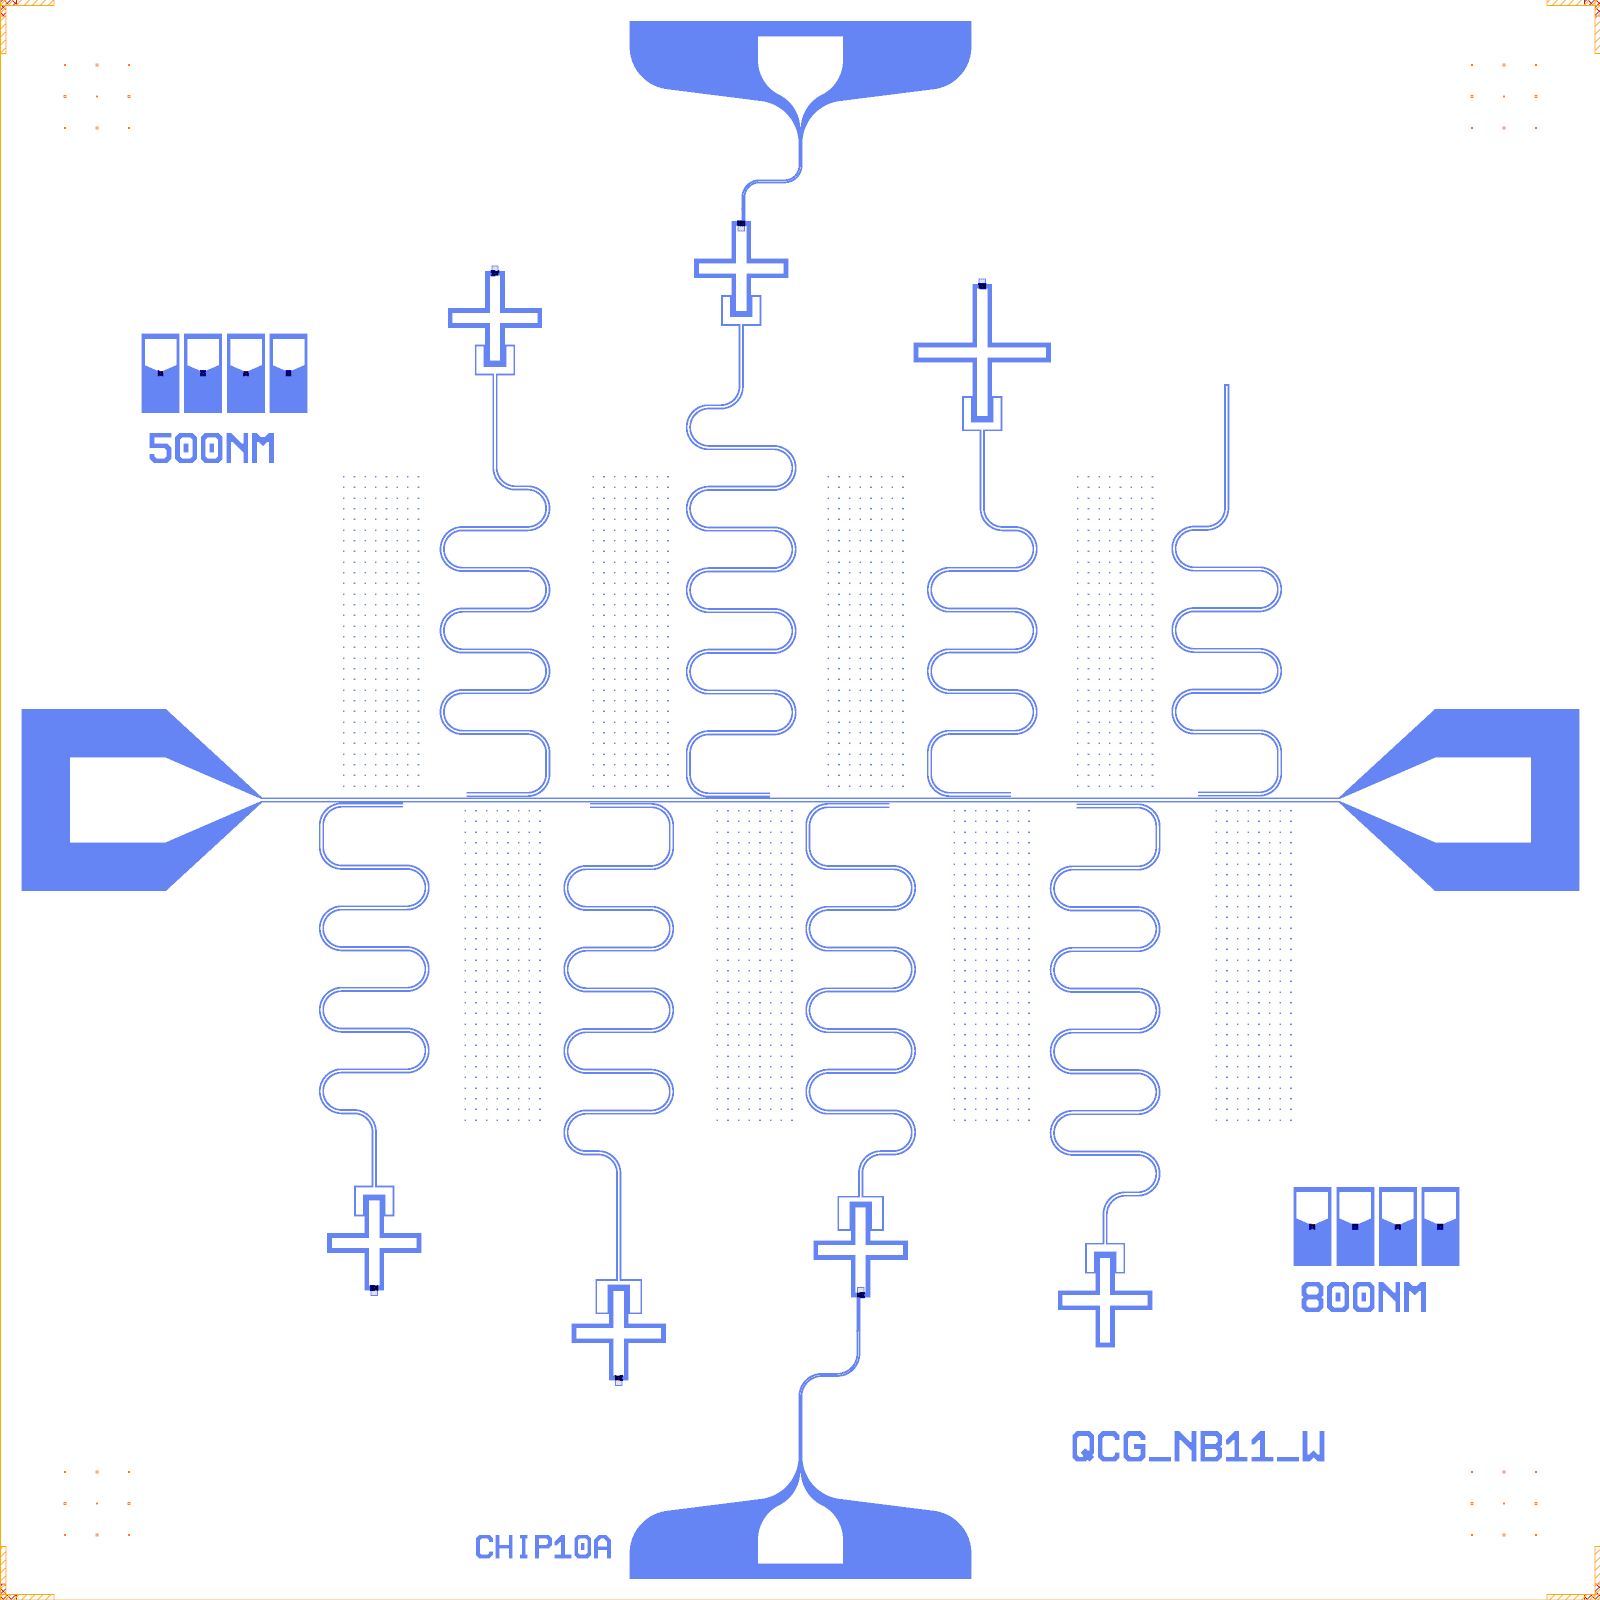

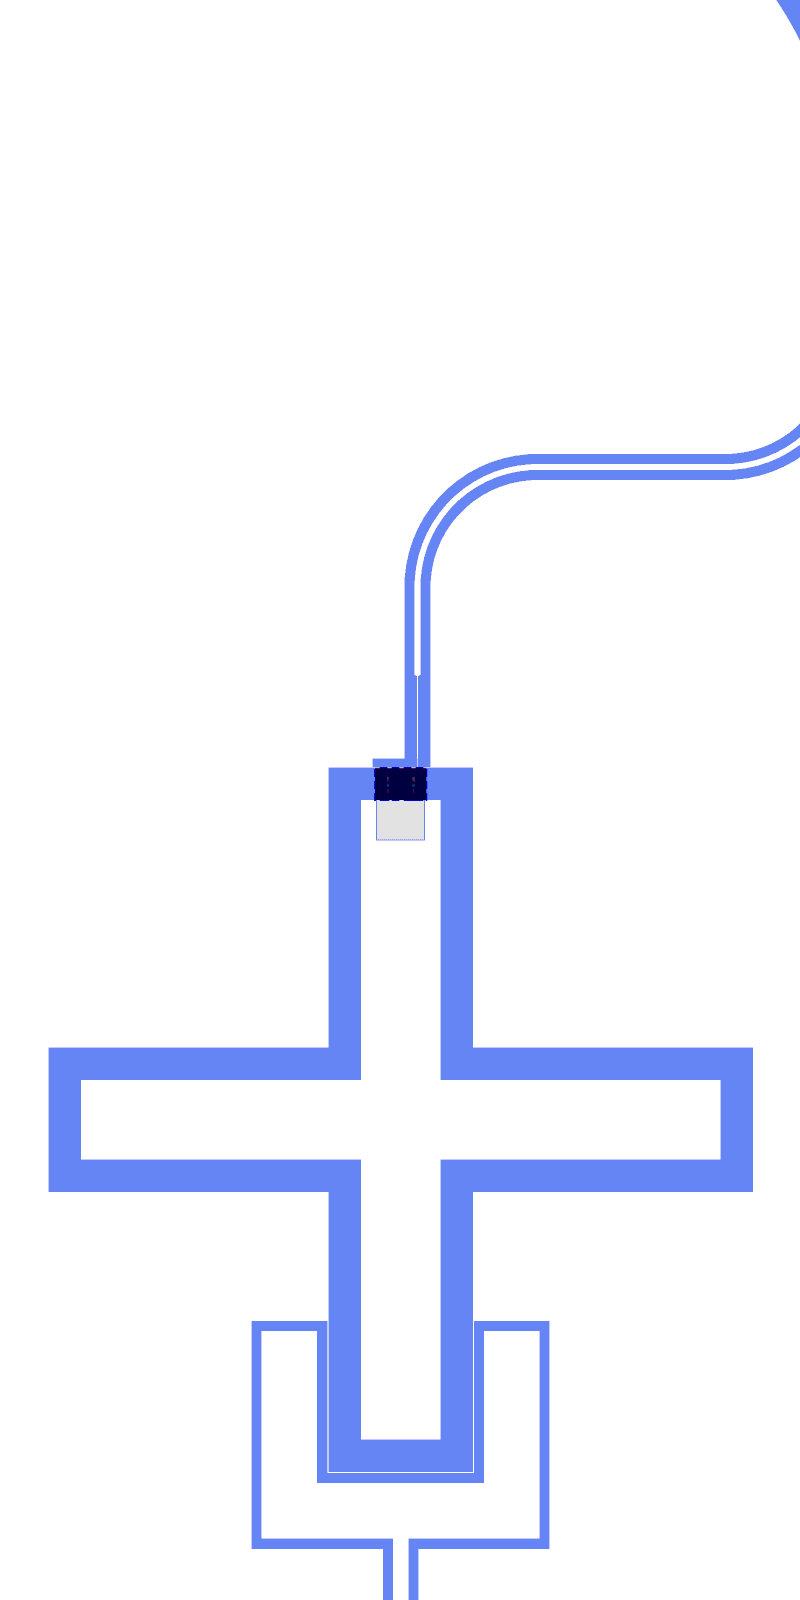

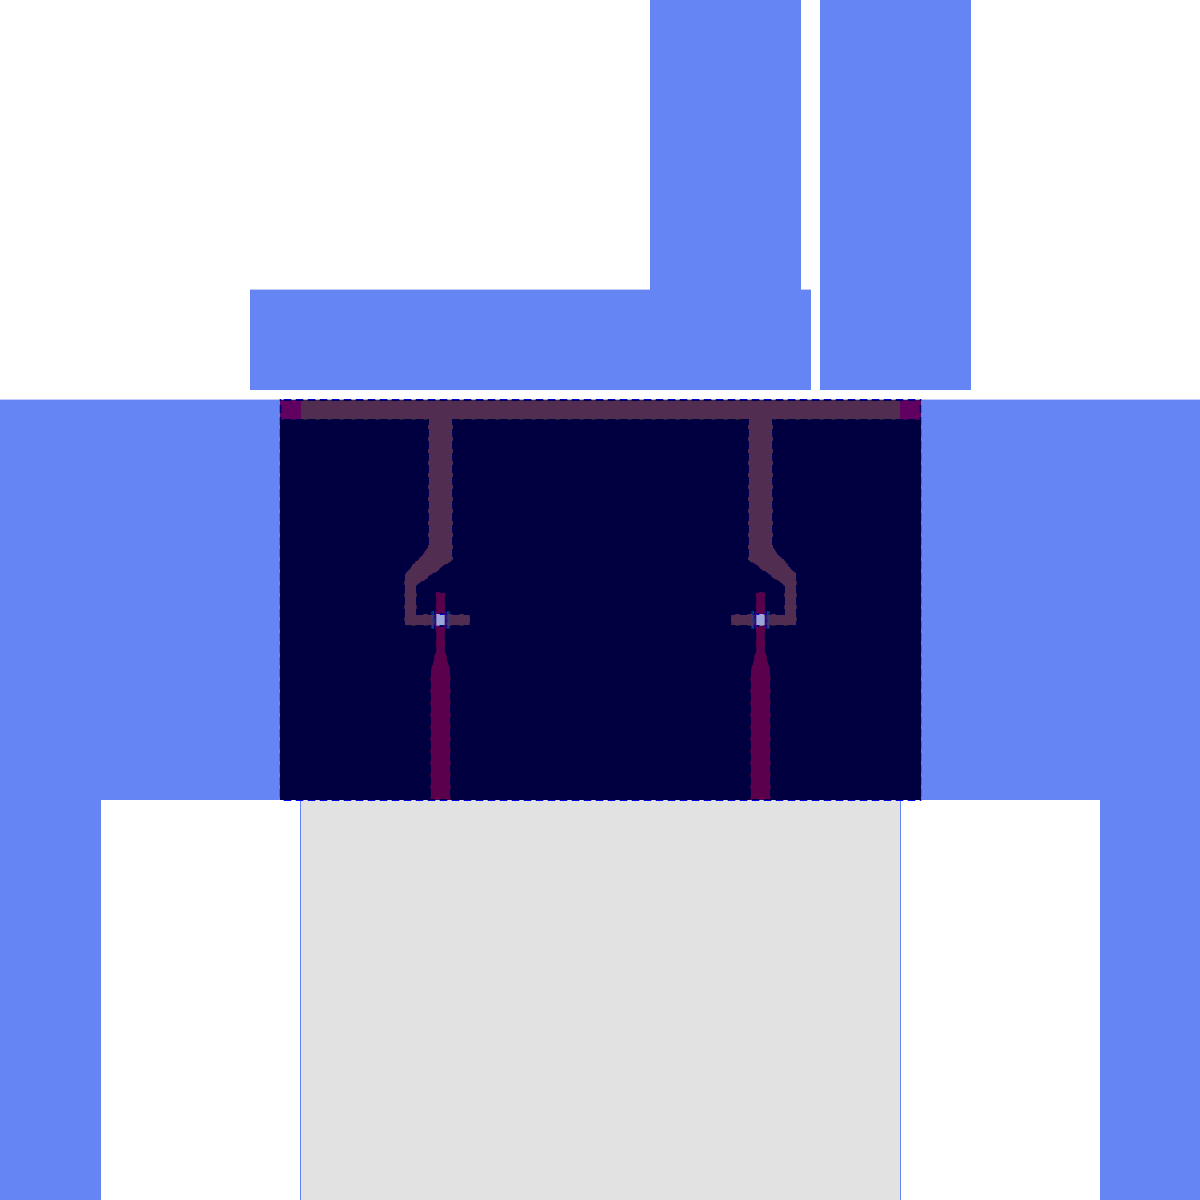

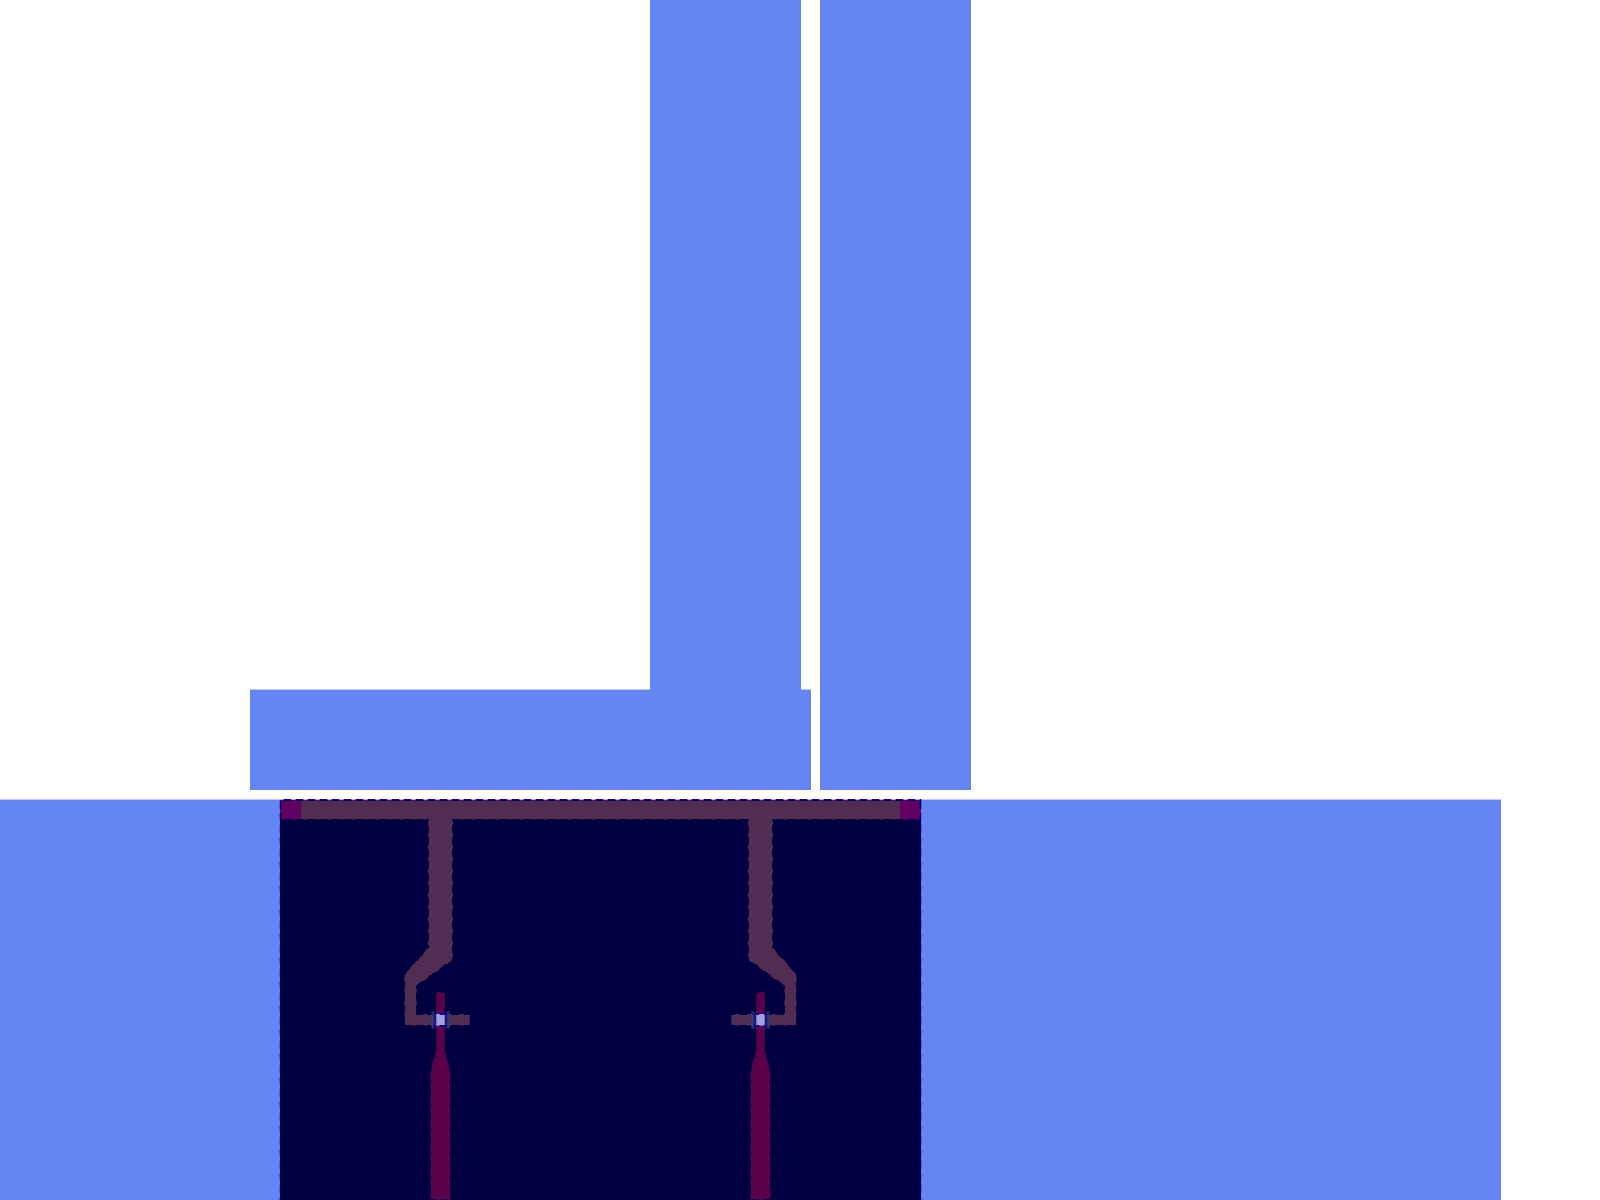

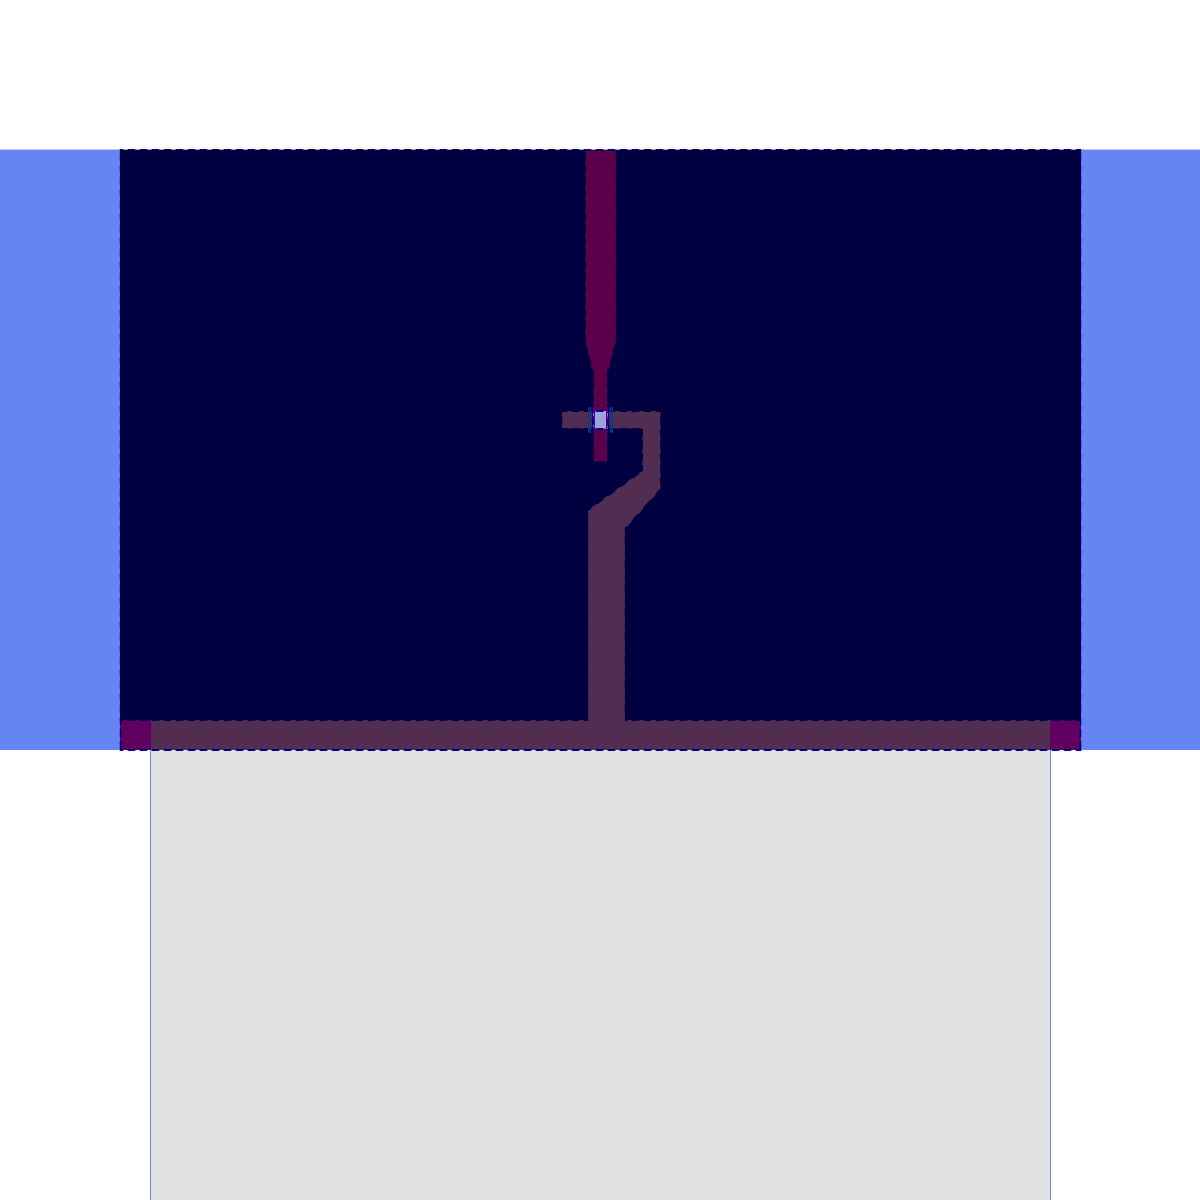

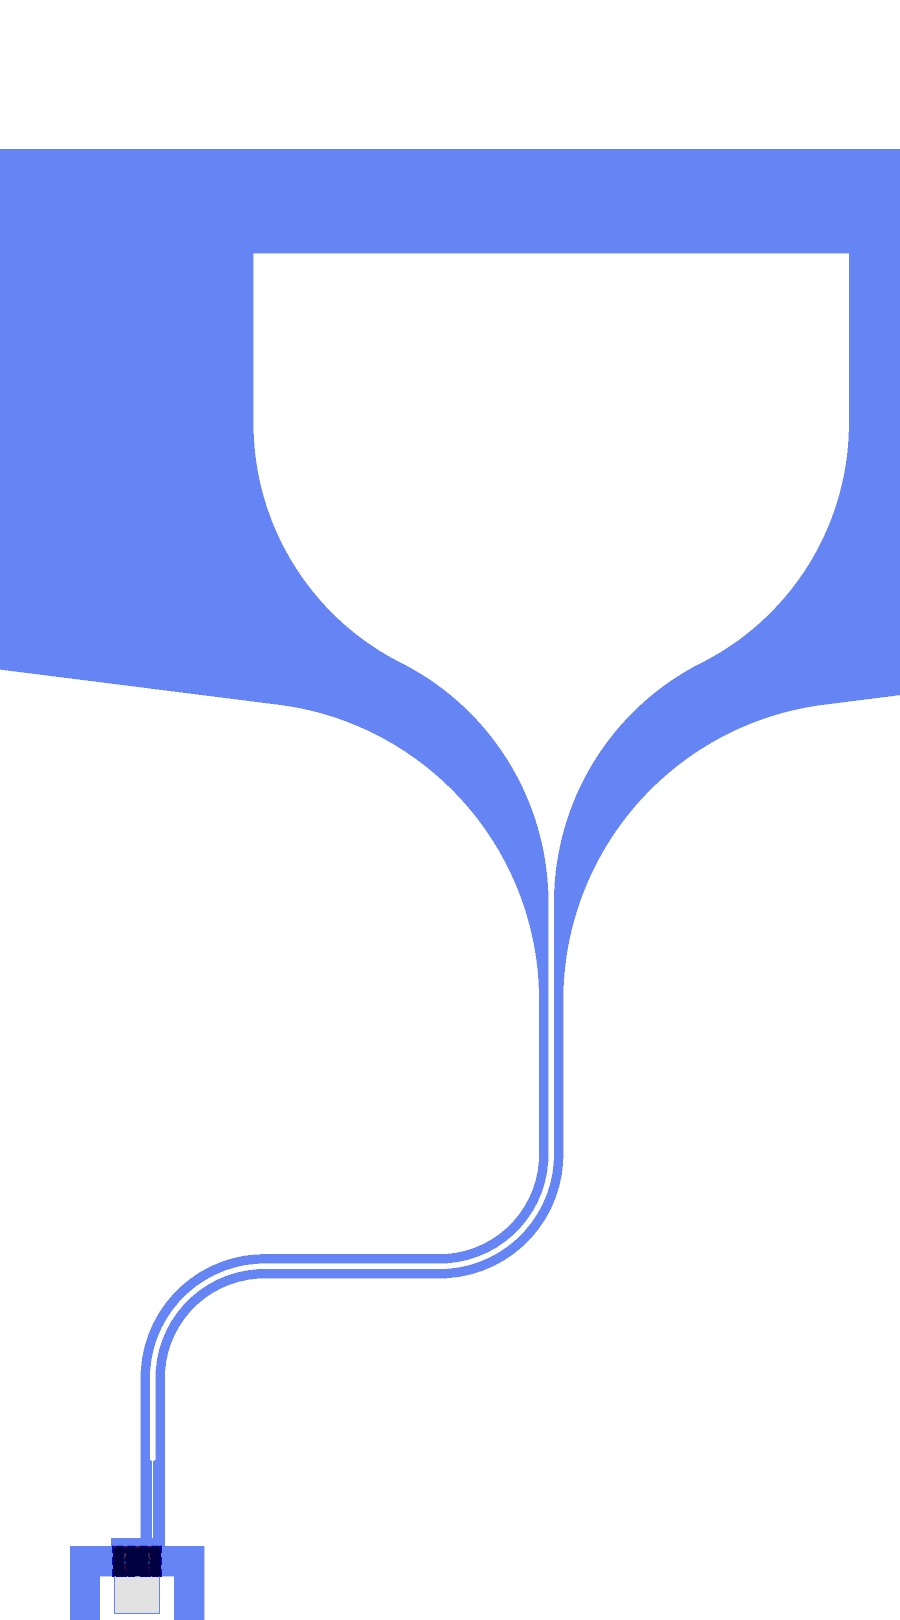

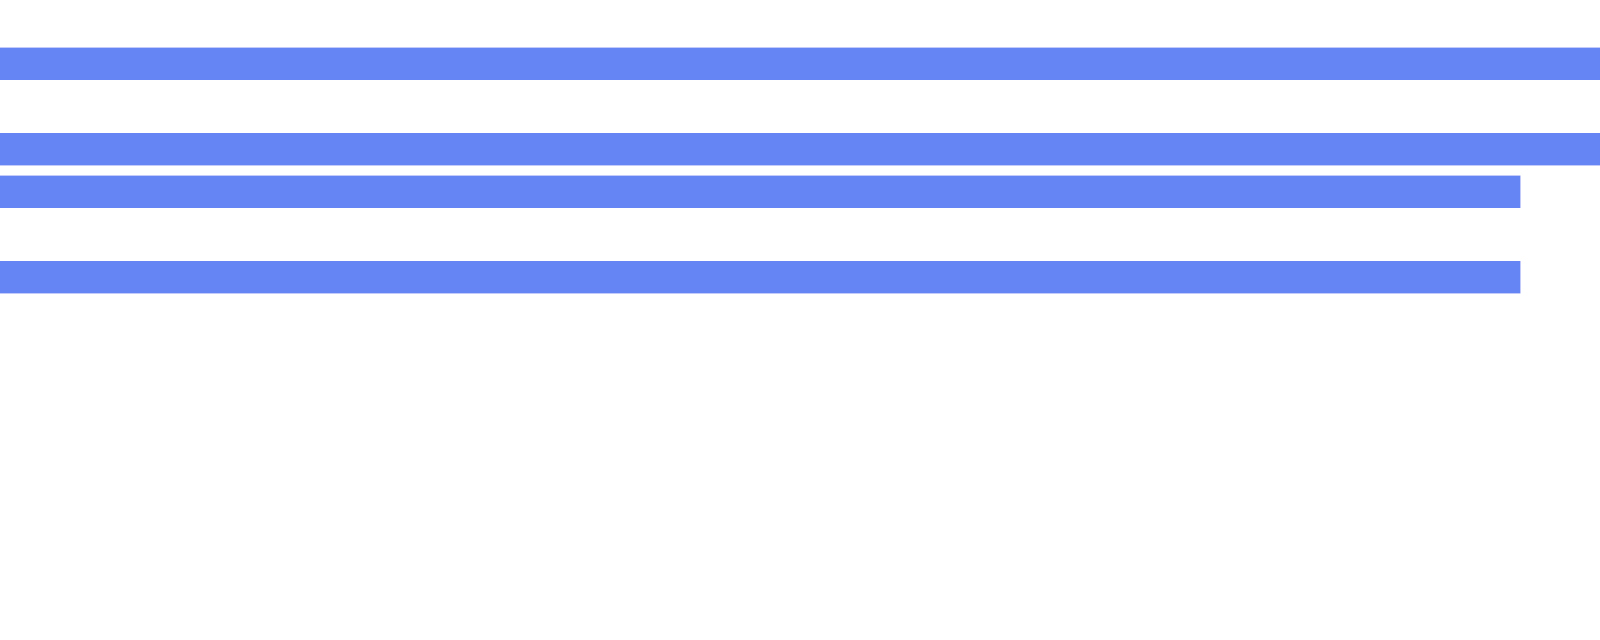

WindowsPath('examples/designs/legacy/chip_10a_flux_tlqubits_coupler.png')

In [17]:
X4, Y4 = L.origin(d, "Q4")                                    # Q4 centre (Designer frame)
X1, Y1 = L.origin(d, "Q1")
XF, YF = C.port_xy(d, "Q4.flux")
XC = C.port_xy(d, "FL.a")[1]                                  # feedline y after centring
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))   # die box (the instance-name layer reaches past it)
C.show_snapshot(d, OUT / f"{ID}_q4.png", box=(X4 - 250, Y4 - 300, X4 + 250, Y4 + 700), size=(800, 1600), width=320)
C.show_snapshot(d, OUT / f"{ID}_squid.png", box=(X4 - 30, Y4 + 180, X4 + 30, Y4 + 240), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_fluxtip.png", box=(X4 - 30, Y4 + 200, X4 + 50, Y4 + 260), size=(1600, 1200), width=400)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(X1 - 20, Y1 - 235, X1 + 20, Y1 - 195), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_fluxpad.png", box=(XF - 100, YF - 50, XF + 500, L.H), size=(900, 1620), width=300)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(1600, XC - 100, 1900, XC + 20), size=(1600, 640))

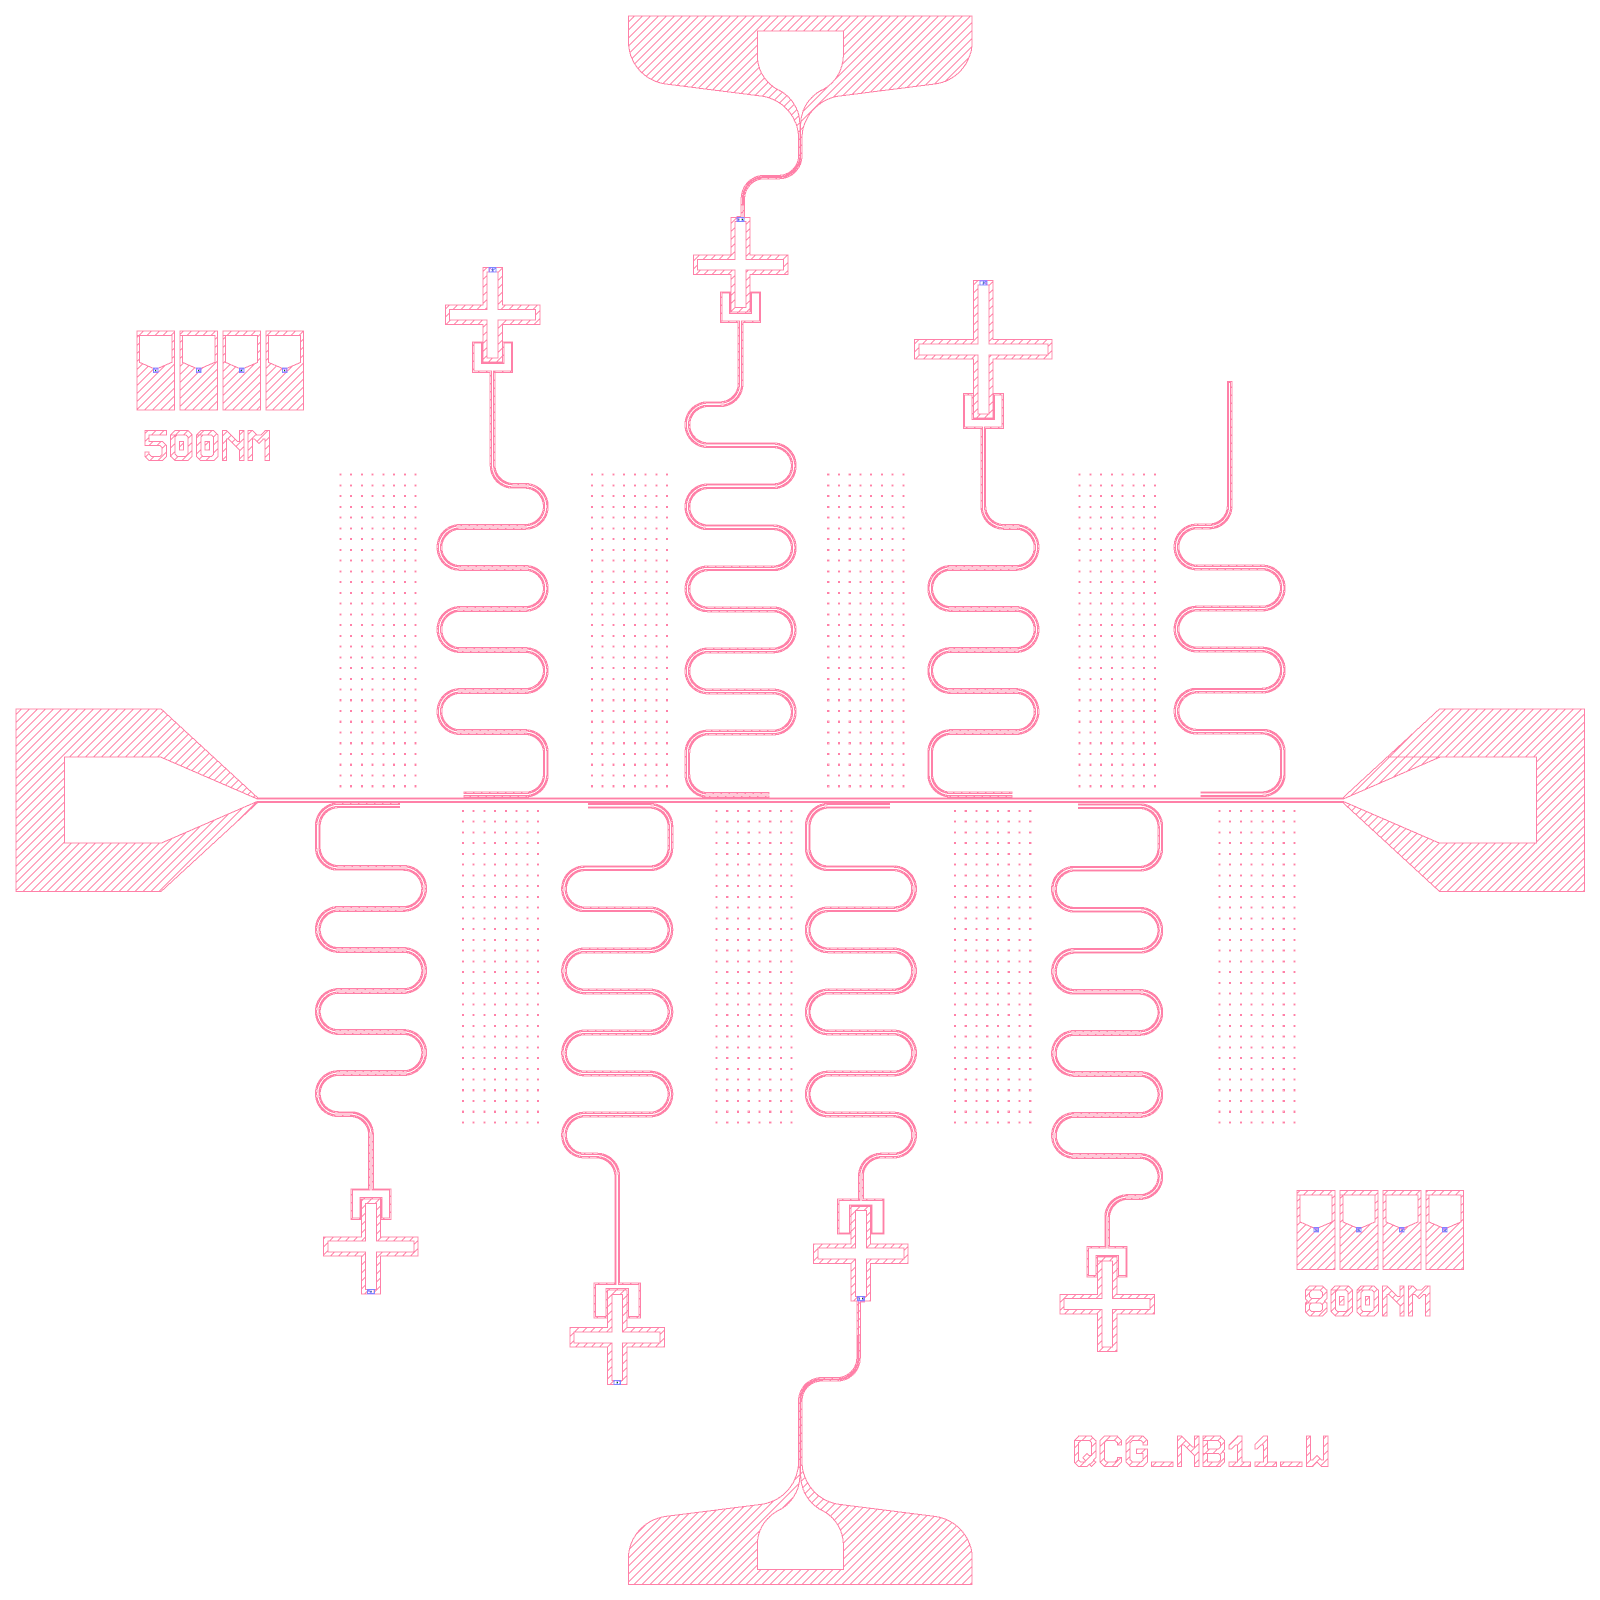

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 60600 | 60600 | 0.0 | 0.00% |
| PL | 497700 | 497700 | 0.0 | 0.00% |
| PR | 497700 | 497700 | 0.0 | 0.00% |
| PFT | 445000 | 445000 | 0.0 | 0.00% |
| PFB | 445000 | 445000 | 0.0 | 0.00% |
| R1 | 56699 | 56699 | 0.0 | 0.00% |
| R2 | 58859 | 58859 | 0.0 | 0.00% |
| R3 | 66899 | 66899 | 0.0 | 0.00% |
| R4 | 71819 | 71819 | 0.0 | 0.00% |
| R5 | 62219 | 62219 | 0.0 | 0.00% |
| R6 | 50820 | 50820 | 0.0 | 0.00% |
| R7 | 69899 | 69899 | 0.0 | 0.00% |
| R8 | 53952 | 53952 | 0.0 | 0.00% |
| Q1 | 38400 | 38400 | 0.0 | 0.00% |
| Q2 | 38400 | 38400 | 0.0 | 0.00% |
| Q3 | 39420 | 39420 | 0.0 | 0.00% |
| Q4 | 38400 | 38400 | 0.0 | 0.00% |
| Q5 | 39420 | 39420 | 0.0 | 0.00% |
| Q6 | 54880 | 54880 | 0.0 | 0.00% |
| Q7 | 39000 | 39000 | 0.0 | 0.00% |
| FLUX4 | 6559 | 6819 | 4024.7 | 61.36% |
| FLUX5 | 11497 | 11499 | 730.1 | 6.35% |
| H0 | 6000 | 6000 | 0.0 | 0.00% |
| H1 | 6000 | 6000 | 0.0 | 0.00% |
| H2 | 6000 | 6000 | 0.0 | 0.00% |
| H3 | 6000 | 6000 | 0.0 | 0.00% |
| H4 | 6000 | 6000 | 0.0 | 0.00% |
| H5 | 6000 | 6000 | 0.0 | 0.00% |
| H6 | 6000 | 6000 | 0.0 | 0.00% |
| H7 | 6000 | 6000 | 0.0 | 0.00% |
| TP1 | 43000 | 43000 | 0.0 | 0.00% |
| TP2 | 43000 | 43000 | 0.0 | 0.00% |
| TP3 | 43000 | 43000 | 0.0 | 0.00% |
| TP4 | 43000 | 43000 | 0.0 | 0.00% |
| TP5 | 43000 | 43000 | 0.0 | 0.00% |
| TP6 | 43000 | 43000 | 0.0 | 0.00% |
| TP7 | 43000 | 43000 | 0.0 | 0.00% |
| TP8 | 43000 | 43000 | 0.0 | 0.00% |
| LBL_500 | 39050 | 39050 | 0.0 | 0.00% |
| LBL_800 | 40100 | 40100 | 0.0 | 0.00% |
| LBL_SIGN | 61050 | 61050 | 0.0 | 0.00% |

max XOR without the flux lines: 0.0 µm²


| instance | layer | legacy (µm²) | rebuilt (µm²) | XOR (µm²) |
|---|---|---|---|---|
| J1 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J2 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J3 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J4 | straight finger 2/0 | 621.973 | 621.973 | 34.4537 |
| J5 | straight finger 2/0 | 621.973 | 621.973 | 0.0000 |
| J6 | straight finger 2/0 | 625.579 | 625.579 | 0.0000 |
| J1 | bent finger 4/0 | 594.329 | 594.329 | 0.0000 |
| J2 | bent finger 4/0 | 594.329 | 594.329 | 0.0000 |
| J3 | bent finger 4/0 | 594.329 | 594.329 | 0.0000 |
| J4 | bent finger 4/0 | 580.658 | 580.658 | 110.0449 |
| J5 | bent finger 4/0 | 580.658 | 580.658 | 0.0000 |
| J6 | bent finger 4/0 | 594.329 | 594.329 | 0.0000 |
| J1 | HSQ spacer (legacy 500/0 → 50/0) | 0.320 | 0.320 | 0.0000 |
| J2 | HSQ spacer (legacy 500/0 → 50/0) | 0.320 | 0.320 | 0.0000 |
| J3 | HSQ spacer (legacy 500/0 → 50/0) | 0.320 | 0.320 | 0.0000 |
| J4 | HSQ spacer (legacy 500/0 → 50/0) | 0.640 | 0.640 | 1.2800 |
| J5 | HSQ spacer (legacy 500/0 → 50/0) | 0.640 | 0.640 | 0.0000 |
| J6 | HSQ spacer (legacy 500/0 → 50/0) | 0.320 | 0.320 | 0.0000 |

max junction-layer XOR without Q4 (#25): 0.0 µm²


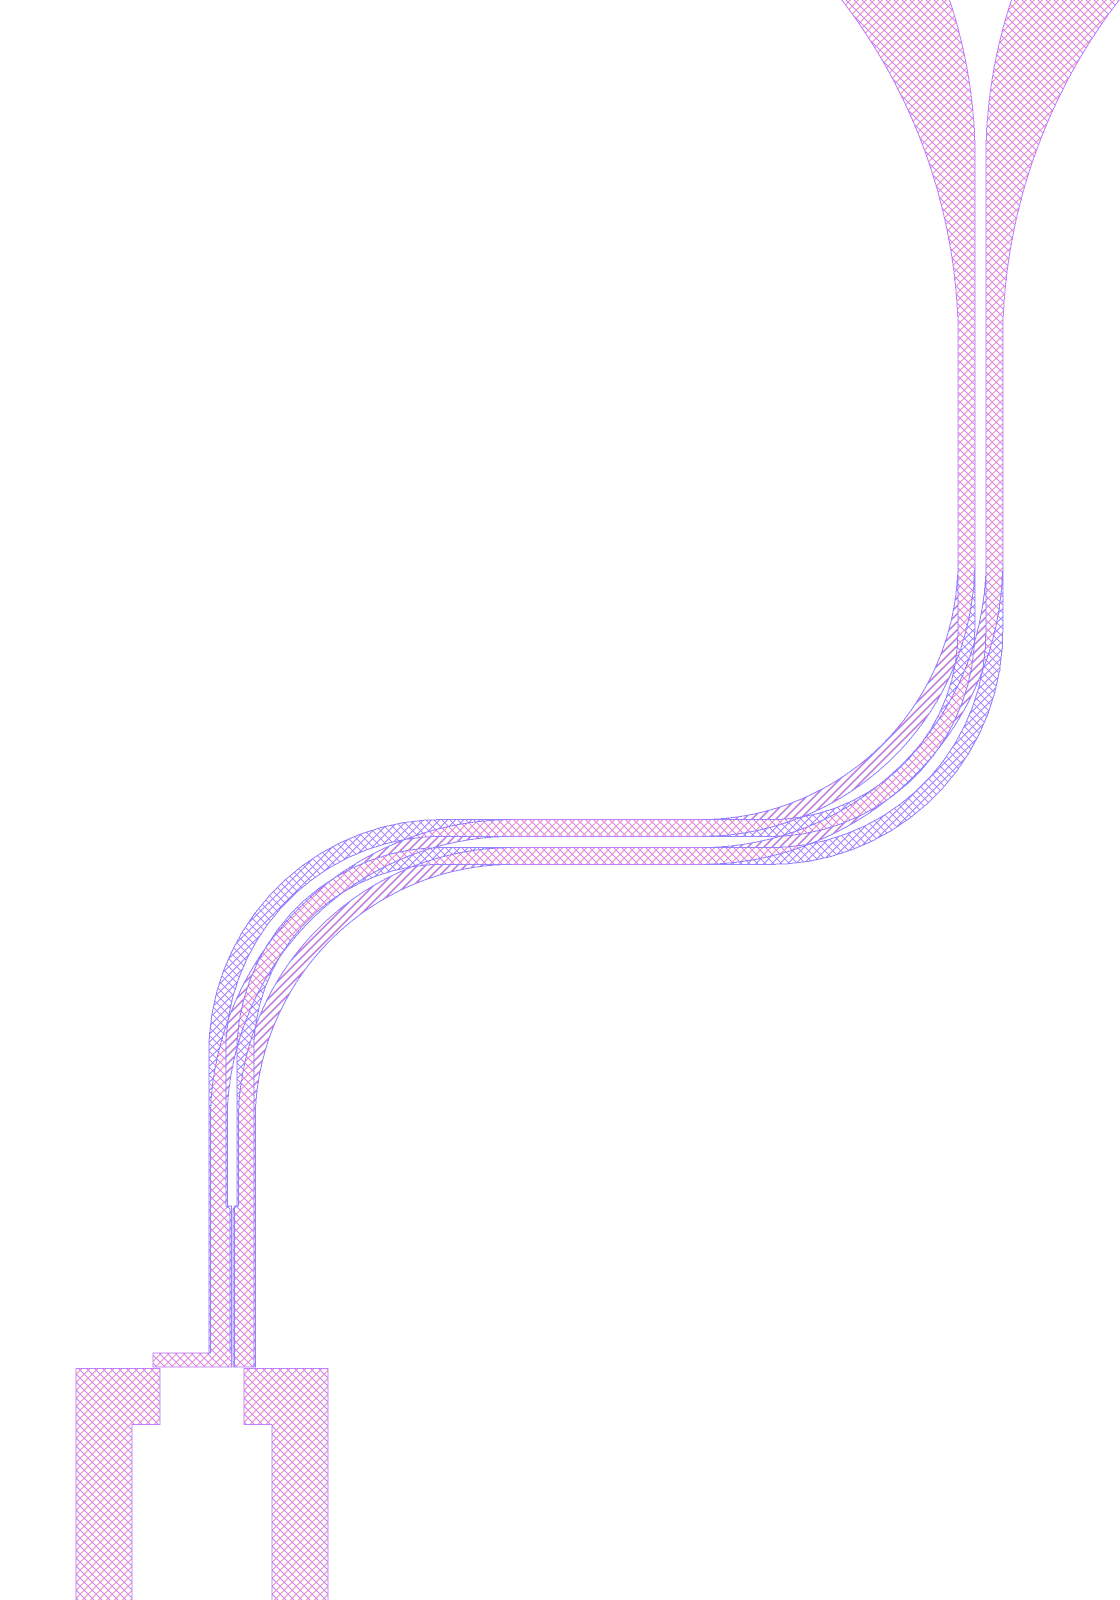

In [18]:
import klayout.db as pya


def legacy_flux_lines(port_y, jog_y):
    """chip_10a_flux_TLQubits.py flux lines (legacy frame, dbu 0.001), transcribed: a 4 µm line in 6 µm gaps with
    100 µm rounded corners, a 1 µm tip, and a 28 × 5 µm ground slot beside the tip; the pad port and the jog at the
    PDK pad position (``port_y`` / ``jog_y``: {4: y, 5: y}, legacy frame)."""
    dbu, g = 0.001, 6
    pts = lambda p: [pya.Point(pya.DPoint(x / dbu, y / dbu)) for x, y in p]
    out = {}
    for key, q, x_jog, (y_tip, y_end), (bx, by) in (
            ("FLUX4", 4, -267, (2770, 2712.5), (-281.5, 2715)),
            ("FLUX5", 5, 271, (-2490, -2330.5), (285.5, -2333))):
        thick = [[0, port_y[q]], [0, jog_y[q]], [x_jog, jog_y[q]], [x_jog, y_tip]]
        thin = [[x_jog, y_tip], [x_jog, y_end]]
        line = (pya.Region(pya.Path(pts(thick), (2 * g + 4) / dbu).round_corners(100 / dbu, 300))
                - pya.Region(pya.Path(pts(thick), 4 / dbu).round_corners(100 / dbu, 300)))
        tip = pya.Region(pya.Path(pts(thin), (2 * g + 4) / dbu)) - pya.Region(pya.Path(pts(thin), 1 / dbu))
        slot = pya.Region(pya.Box(int(28 / dbu), int(5 / dbu)).moved(round(bx / dbu), round(by / dbu)))
        out[key] = line + tip + slot
    return out


if L.legacy_available():
    from quantcore_circuits.live.snapshot import snapshot
    legacy_y = lambda ref: C.port_xy(d, ref)[1] - L.H / 2 - SHIFT[1]                   # Designer → legacy frame
    PORT_Y = {4: legacy_y("PFT.a"), 5: legacy_y("PFB.a")}                              # flux pads at the PDK rule
    JOG_Y = {q: y - L.H / 2 for q, y in JOG.items()}                                 # set before the centring
    ref = LB.legacy_chip(ID)
    ref.pcell("FL", "Coplanar Waveguide", {"fab": True, **FEED | {"length": 2 * x_pad}})   # PDK pad position
    ref.pcell("PL", "Connector Pad 2", {"fab": True, **PAD2}, -x_pad, 0, 3)
    ref.pcell("PR", "Connector Pad 2", {"fab": True, **PAD2}, x_pad, 0, 1)
    ref.pcell("PFT", "Connector Pad", {"fab": True, **TINY}, 0, PORT_Y[4], 2, False)
    ref.pcell("PFB", "Connector Pad", {"fab": True, **TINY}, 0, PORT_Y[5], 2, True)
    for n, x, strip, above, over, f in RROWS:
        ref.pcell(f"R{n}", "Coupled Resonator", {"fab": True, **RES, **over}, x, (22 + strip) * (1 if above else -1),
                  0, above)
    for i, (x, y, cross, js) in enumerate(QUBITS, 1):
        ref.pcell(f"Q{i}", "Xmon Cross", {"fab": True, **cross}, x, y, 0 if i % 2 else 2, False)
    for key, region in legacy_flux_lines(PORT_Y, JOG_Y).items():
        ref.etch_region(key, region)
    for k, (x, y) in enumerate(HOLES):
        ref.holes(f"H{k}", x - 50, y, 8, 30, 50, 50, 5)
    for k, (x, y, bf) in enumerate(TESTPADS, 1):
        ref.cell_from(f"TP{k}", *L.legacy_script_cell("xtp_testpads_TL_small.py", "create_testPad", "TEST_TL", bf / 0.2,
                                                       SECOND_FINGER, tmp=f"build/legacy_b/chip_10a/tp{k}"), x, y)
    for name, text, x, y in LABELS:
        ref.text(name, text, 200, False, x, y)
    # junctions: xjc scripts at (x, y ± 210) (+100 for Q6), Trans(0, flag, ...) with the source's toggling flag
    flags = [False, True, False, False, False, True]
    for i, (x, y, cross, js) in enumerate(QUBITS[:-1], 1):
        script, func = ("xjc_squid_TL_mod.py", "create_squid") if i in SQUIDS else ("xjc_junction_TL_mod.py", "create_junction")
        cell = LB.legacy_path_cell(script, func, f"JUNC_{js}", js, SECOND_FINGER, tmp=f"build/legacy_b/chip_10a/j{i}")
        ref.cell_from(f"J{i}", *cell, x, y + (210 if y > 0 else -210) + (100 if i == 6 else 0), 0, flags[i - 1])
    cuts = []                                       # CLEARER: 30 × 45 µm, from the cross end into the ground
    for i, (x, y, cross, js) in enumerate(QUBITS[:-1]):                  # (SQUIDs: shifted 25 µm into the cross)
        yc = y + (25 * (-1) ** i if i in (3, 4) else 0) + (100 if i == 5 else 0)
        yc += 222.5 if yc > 0 else -222.5
        cuts.append((x - 15, yc - 22.5, x + 15, yc + 22.5))
    ref.cut(cuts)
    ref = L.shift_reference(ref, *SHIFT)
    snapshot(ref.write(f"build/legacy_b/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref, names=[n for n in ref.boxes if not n.startswith("J")])
    display(Markdown(table))
    print("max XOR without the flux lines:", round(max(v for k, v in xor.items() if not k.startswith("FLUX")), 3), "µm²")
    jtable, jxor = LB.junction_xor(d, ref, names=[f"J{i}" for i in range(1, 7)])
    display(Markdown(jtable))
    print("max junction-layer XOR without Q4 (#25):", round(max(v for (n, _), v in jxor.items() if n != "J4"), 4), "µm²")
    L.xor_png(d, ref, OUT / f"{ID}_xor_flux4.png", box=(XF - 82.5, YF - 82.5, XF + 317.5, YF + 487.5), size=(1120, 1600))
    display(Image(filename=str(OUT / f"{ID}_xor_flux4.png"), width=360))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the resonators, Xmon crosses and claws with their junction windows, the flux holes, the
  eight test pads, the labels and the four pads + feedline at their PDK position (XOR 0 µm² on every one); the
  junction cells on 2/0, 4/0 and the HSQ layer (XOR 0 except Q4, whose legacy SQUID is upside down, #25: 34 / 110 /
  1.3 µm²).
- **Differs, by the PDK:** the four pads `pad_edge` = 100 µm from the die edge (feedline 5250 → 5050 µm; flux-pad
  ports at ±3055 µm instead of ±3155); the flux lines' jogs moved with their pads (y +2900 / −2695, legacy frame:
  the same 155 / 360 µm leads, so the 75 / 100 µm corners fit; 546 / 910 µm long); the PDK frame and device ID
  `CHIP10A` (bottom edge, left of the flux pad). Centring shift (0, 0): the chip is symmetric.
- **Differs, legacy approximations:** FLUX4's 75 µm corners (#11), the route on the tip's x (0.5 µm off the legacy
  path) and the 1 µm taper to the tip (XOR FLUX4 4025 µm², FLUX5 730 µm²).
- **Cheese:** the original's flux holes, no PDK band (fab cheese source "original"; before this pass the build
  added the band).
- **Open:** 3 `pdk_rn` design warnings (Q4 / Q5 22.5 kΩ, Q6 28.1 kΩ); Q1/R1 and Q2/R2 collide; Q6 at the PDK
  nominal 45 kΩ would sit at 4.91 GHz instead of 6.06 GHz (step 13).